In [1]:
import importlib
import inspect
import os
from argparse import Namespace
import numpy as np

%load_ext autoreload
%autoreload 2



def get_all_dataset_names():
    return [
        dataset.split(".")[0]
        for dataset in os.listdir("dataset")
        if not dataset.find("__") > -1 and "py" in dataset
    ]


def get_all_datasets():
    datasets = {}
    for dataset in get_all_dataset_names():
        mod = importlib.import_module("dataset." + dataset)
        dataset_classes_name = [
            x
            for x in mod.__dir__()
            if "type" in str(type(getattr(mod, x)))
            and "DatasetBase" in str(inspect.getmro(getattr(mod, x))[1:])
        ]
        for d in dataset_classes_name:
            c = getattr(mod, d)
            datasets[c.NAME] = c
    return datasets


def get_dataset(dataset_name, accelerator, args: Namespace):
    """
    Returns the dataset object.
    """
    datasets_set = get_all_datasets()
    assert (
        dataset_name in datasets_set
    ), f"Dataset {dataset_name} not found. Available datasets: {datasets_set.keys()}"
    return datasets_set[dataset_name](accelerator, args)


In [2]:
from accelerate import Accelerator
accelerator = Accelerator()

# Configure args for Qwen2 model and dataset
args = Namespace()
args.model = "Qwen/Qwen2.5-0.5B"  # Using smaller Qwen2 model for testing
args.dataset = "MMLU-chem"  # Boolean Questions dataset (2-class classification)
args.add_space = False
args.max_seq_len = 300
args.batch_size = 16
args.is_s2s = False  # Qwen2 is decoder-only, not sequence-to-sequence
args.testing_set = "val"

print(f"Using model: {args.model}")
print(f"Using dataset: {args.dataset}")
# Create the dataset
try:
    dataset = get_all_datasets()['mcdataset'](accelerator, args)
    print(f"✅ Successfully created dataset with {dataset.num_labels} labels")
    
    # Get the dataloaders
    dataset.get_loaders()
    print(f"✅ Successfully created dataloaders")
    print(f"📊 Number of training samples: {dataset.num_samples}")
    print(f"🎯 Target token IDs: {dataset.target_ids}")
    
except Exception as e:
    print(f"❌ Error creating dataset: {e}")
    print("Available datasets:", list(get_all_datasets().keys()))

Using model: Qwen/Qwen2.5-0.5B
Using dataset: MMLU-chem
Loaded MMLU-chem dataset.
✅ Successfully created dataset with 4 labels
✅ Successfully created dataloaders
📊 Number of training samples: 96
🎯 Target token IDs: tensor([[32],
        [33],
        [34],
        [35]])


In [3]:
dataset.target_ids

tensor([[32],
        [33],
        [34],
        [35]])

In [105]:
# Explore the dataset structure
if 'dataset' in locals():
    print("=== Dataset Information ===")
    print(f"Dataset type: {type(dataset)}")
    print(f"Number of labels: {dataset.num_labels}")
    print(f"Tokenizer: {type(dataset.tokenizer)}")
    print(f"Tokenizer vocab size: {dataset.tokenizer.vocab_size}")
    
    # Check special tokens
    print("\n=== Special Tokens ===")
    print(f"BOS token: '{dataset.tokenizer.bos_token}' (ID: {dataset.tokenizer.bos_token_id})")
    print(f"EOS token: '{dataset.tokenizer.eos_token}' (ID: {dataset.tokenizer.eos_token_id})")
    print(f"PAD token: '{dataset.tokenizer.pad_token}' (ID: {dataset.tokenizer.pad_token_id})")
    print(f"UNK token: '{dataset.tokenizer.unk_token}' (ID: {dataset.tokenizer.unk_token_id})")
    
    # Target tokens for classification
    print(f"\n=== Target Tokens for Classification ===")
    print(f"Target IDs shape: {dataset.target_ids.shape}")
    print(f"Target token IDs: {dataset.target_ids.tolist()}")
    
    # Decode target tokens
    for i, target_id in enumerate(dataset.target_ids):
        decoded = dataset.tokenizer.decode(target_id, skip_special_tokens=True)
        print(f"Label {i}: token_id={target_id.item()} -> '{decoded}'")
    
    # Show a sample batch from train dataloader
    print("\n=== Sample Training Batch ===")
    try:
        sample_batch = next(iter(dataset.train_dataloader))
        print(f"Batch type: {type(sample_batch)}")
        print(f"Batch length: {len(sample_batch)}")
        
        # Handle BatchEncoding object
        batch_encoding = sample_batch[0]
        labels = sample_batch[1] if len(sample_batch) > 1 else None
        extra = sample_batch[2] if len(sample_batch) > 2 else None
        
        print(f"\nBatchEncoding keys: {list(batch_encoding.keys())}")
        
        # Get input_ids and attention_mask
        input_ids = batch_encoding['input_ids']
        attention_mask = batch_encoding.get('attention_mask', None)
        
        print(f"Input IDs shape: {input_ids.shape}")
        if attention_mask is not None:
            print(f"Attention mask shape: {attention_mask.shape}")
        if labels is not None:
            print(f"Labels shape: {labels.shape}")
            print(f"Sample labels: {labels[:5].tolist()}")
        if extra is not None:
            print(f"Extra tensor shape: {extra.shape}")
        
        # Show first sample
        print(f"\nFirst sample input IDs (first 20): {input_ids[0][:20].tolist()}")
        if attention_mask is not None:
            print(f"First sample attention mask (first 20): {attention_mask[0][:20].tolist()}")
        
        # Decode first sample
        decoded_text = dataset.tokenizer.decode(input_ids[0], skip_special_tokens=False)
        print(f"\nDecoded sample:\n{decoded_text}...")
        
        # Show the actual length vs padded length
        actual_length = attention_mask[0].sum().item() if attention_mask is not None else len(input_ids[0])
        print(f"\nSequence info:")
        print(f"Total length: {len(input_ids[0])}")
        print(f"Actual length (non-padded): {actual_length}")
        
    except Exception as e:
        print(f"Error exploring batch: {e}")
        import traceback
        traceback.print_exc()
else:
    print("❌ Dataset not created yet. Run the previous cell first.")

=== Dataset Information ===
Dataset type: <class 'dataset.S2SDataset_Classification.S2SDataset_Classification'>
Number of labels: 2
Tokenizer: <class 'transformers.models.qwen2.tokenization_qwen2_fast.Qwen2TokenizerFast'>
Tokenizer vocab size: 151643

=== Special Tokens ===
BOS token: 'None' (ID: None)
EOS token: '<|endoftext|>' (ID: 151643)
PAD token: '<|endoftext|>' (ID: 151643)
UNK token: 'None' (ID: None)

=== Target Tokens for Classification ===
Target IDs shape: torch.Size([2, 1])
Target token IDs: [[2514], [4049]]
Label 0: token_id=2514 -> 'True'
Label 1: token_id=4049 -> 'False'

=== Sample Training Batch ===
Batch type: <class 'tuple'>
Batch length: 3

BatchEncoding keys: ['input_ids', 'attention_mask']
Input IDs shape: torch.Size([4, 300])
Attention mask shape: torch.Size([4, 300])
Labels shape: torch.Size([4])
Sample labels: [1, 1, 1, 1]
Extra tensor shape: torch.Size([4])

First sample input IDs (first 20): [151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 15

In [4]:
sample_batch, label, target_id = next(iter(dataset.train_dataloader))
print(sample_batch['input_ids'].shape)
print(sample_batch['attention_mask'].shape)
print(label)
print(target_id)

torch.Size([16, 300])
torch.Size([16, 300])
tensor([3, 2, 3, 1, 1, 1, 0, 3, 2, 3, 3, 1, 0, 3, 3, 2])
tensor([35, 34, 35, 33, 33, 33, 32, 35, 34, 35, 35, 33, 32, 35, 35, 34])


### run with stored dataset

In [5]:
from src.qwen_jax import load_params_and_config, QwenForCausalLM
import jax
import jax.numpy as jnp
import numpy as np

%load_ext autoreload
%autoreload 2

params, config = load_params_and_config("datasets/model_exports/qwen2.5_0.5B_bfloat16")
jax_model = QwenForCausalLM(**config)
params

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


FrozenDict({
    params: {
        embed_tokens: {
            embedding: Array([[-0.0100708, 0.0419922, 0.0098877, ..., 0.00994873, 0.0151367,
                    -0.00704956],
                   [-0.0146484, 6.03199e-05, -0.0184326, ..., -0.00169373,
                    0.00311279, -0.00842285],
                   [-0.0366211, -0.00982666, 0.00698853, ..., -0.00775146,
                    -0.0170898, -0.000104904],
                   ...,
                   [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
                    0.0172119],
                   [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
                    0.0172119],
                   [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
                    0.0172119]], dtype=bfloat16),
        },
        layers_0: {
            input_layernorm: {
                weight: Array([-0.0461426, 0.0437012, -0.0244141, 0.0825195, -0.0410156,
                       0.0375977

In [6]:
with np.load("datasets/text_classification/boolq/train_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])
    all_target_ids = jnp.array(data['target_ids'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape, all_target_ids.shape

((9424, 525), (9424, 525), (9424,), (9424,), (2, 1))

In [7]:
# Test forward pass with loaded Qwen model and dataset batch
# Assumes: jax_model, params, input_ids, attention_mask are already defined

# Forward pass (no gradient, inference mode)
outputs, inter = jax_model.apply(params, input_ids[:4], attention_mask[:4], train=False, mutable=['intermediates'])
print("Forward pass output shape:", outputs.shape)
print("Sample", outputs[0][-1])

Forward pass output shape: (4, 525, 151936)
Sample [4.21875 4.125 2.8125 ... -5.53125 -5.53125 -5.53125]


In [59]:
arr = inter['intermediates']['layers_0']['self_attn']['attn_weights_prob'][0][0, 0, 250:260, 250:260]
arr = np.array(arr)
print(f"{np.array2string(arr, precision=2)}")

[]


In [9]:
# Test forward pass with loaded Qwen model and dataset batch
# Assumes: jax_model, params, input_ids, attention_mask are already defined

# Forward pass (no gradient, inference mode)
outputs = jax_model.apply(params, input_ids[:4], attention_mask[:4], train=False)
print("Forward pass output shape:", outputs.shape)
print("Sample", outputs[0, -1])

Forward pass output shape: (4, 525, 151936)
Sample [4.21875 4.125 2.8125 ... -5.53125 -5.53125 -5.53125]


In [12]:
logit = outputs[:,-1, all_target_ids.flatten()]
logit.shape

(4, 2)

In [15]:
import optax
nll_optax = optax.losses.softmax_cross_entropy_with_integer_labels(logit.astype(jnp.float32), labels[:4])
nll_optax

Array([0.25192928, 0.19029903, 0.16022396, 0.22541237], dtype=float32)

In [17]:
nll_optax = optax.losses.softmax_cross_entropy_with_integer_labels(logit, labels[:4])
nll_optax

Array([0.25, 0.1875, 0.1875, 0.25], dtype=bfloat16)

In [18]:
# verify cross entropy loss
probs = jax.nn.softmax(logit, axis=-1)
nll_normal = -jnp.log(jnp.take_along_axis(probs, labels[:4].reshape(-1, 1), axis=1)).flatten()
print(f"allclose(nll_normal, nll_optax): {jnp.allclose(nll_normal, nll_optax, rtol=1e-2)}")
nll_normal

allclose(nll_normal, nll_optax): False


Array([0.251953, 0.193359, 0.161133, 0.22168], dtype=bfloat16)

In [14]:
selected = jnp.take_along_axis(outputs[:, -1], target_id[:4].reshape(-1, 1), axis=-1)
selected

Array([[9.555],
       [7.13 ],
       [7.43 ],
       [9.664]], dtype=float16)

In [10]:
all_ids = jnp.unique(target_id)
print("All unique target IDs:", all_ids)
probs = jax.nn.softmax(outputs[:, -1, all_ids], axis=-1)
print(f"Probabilities {probs} shape:{probs.shape}")
# target mask 
target_mask = jnp.argmax(target_id[:4].reshape(-1, 1) == all_ids.reshape(1, -1), axis=-1, keepdims=True)
print("Target mask indices:", target_mask.shape)

jnp.take_along_axis(probs, target_mask, axis=-1)

All unique target IDs: [32 33]
Probabilities [[0.07916 0.921  ]
 [0.06934 0.931  ]
 [0.1082  0.892  ]
 [0.0857  0.914  ]] shape:(4, 2)
Target mask indices: (4, 1)


Array([[0.921  ],
       [0.06934],
       [0.1082 ],
       [0.914  ]], dtype=float16)

In [11]:
selected = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
selected

Array([[7.1  , 9.555],
       [7.13 , 9.73 ],
       [7.43 , 9.54 ],
       [7.297, 9.664]], dtype=float16)

### run with torch

In [12]:
# from transformers import  Qwen2ForCausalLM

# modell = Qwen2ForCausalLM(model.config)

In [ ]:
from transformers import Qwen2ForCausalLM

In [21]:
# Run equivalent forward pass using PyTorch (Transforms Qwen model)
import gc
gc.collect()
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForCausalLM

%load_ext autoreload
%autoreload 2

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model_cfg = {
    'device_map': 'auto',
    'torch_dtype': torch.float16 if torch.cuda.is_available() else torch.float32,
    'trust_remote_code': False,
}
print("Loading PyTorch model (this may print a lot)...")
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_cfg)
model.eval()

# Prepare inputs (use data loaded earlier in the notebook)
# input_ids, attention_mask, labels, target_id were loaded from the dataset .npz
torch_input_ids = torch.from_numpy(np.array(input_ids[:4])).to(device)
torch_attention_mask = torch.from_numpy(np.array(attention_mask[:4])).to(device)

# Forward pass (no grad)
with torch.no_grad():
    torch_out = model(input_ids=torch_input_ids, attention_mask=torch_attention_mask)
    # torch_out = model(input_ids=torch_input_ids, attention_mask=torch.ones(4,300))

# Get logits (batch, seq_len, vocab)
torch_logits = torch_out.logits if hasattr(torch_out, 'logits') else torch_out[0]
print("Torch logits shape:", torch_logits.shape)

# Select last token logits (equivalent to outputs[:, -1] in JAX run)
torch_last = torch_logits[:, -1, :].cpu().numpy()
print("Selected last-token logits shape (torch):", torch_last.shape)

# If JAX outputs exist, compare numerically (outputs from JAX should be in variable `outputs`)
try:
    jax_last = np.array(outputs[:4, -1, :])
    abs_diff = np.abs(torch_last - jax_last)
    print("Comparison with JAX last-token logits:")
    print("  max abs diff:", float(abs_diff.max()))
    print("  mean abs diff:", float(abs_diff.mean()))
except NameError:
    print("JAX outputs not found in workspace; skipping numeric comparison.")

# Compute probabilities for the small set of target ids used earlier
all_ids = np.unique(np.array(target_id))
print("All unique target IDs:", all_ids)
torch_all_ids = torch.tensor(all_ids, dtype=torch.long).to(device)
torch_probs = torch.softmax(torch_logits[:, -1, :][:, torch_all_ids], dim=-1).cpu().numpy()
print("Probabilities shape (batch, n_targets):", torch_probs.shape)

# Map target_id entries to indices into all_ids (same mapping as JAX code) and pick the prob
torch_target_ids = np.array(target_id[:4]).reshape(-1, 1)
# mapping via argmax on equality
target_mask = (torch_target_ids == all_ids.reshape(1, -1)).argmax(axis=1).reshape(-1, 1)
selected_probs = np.take_along_axis(torch_probs, target_mask, axis=-1).squeeze(-1)
print("Selected target probabilities (per-sample):", selected_probs.tolist())

# Also show logits at the target positions
selected_logits = np.take_along_axis(torch_last, torch_target_ids, axis=-1).squeeze(-1)
print("Selected target logits (per-sample):", selected_logits.tolist())

Target Device: cuda


`torch_dtype` is deprecated! Use `dtype` instead!


Loading PyTorch model (this may print a lot)...
Torch logits shape: torch.Size([4, 201, 151936])
Selected last-token logits shape (torch): (4, 151936)
JAX outputs not found in workspace; skipping numeric comparison.
All unique target IDs: [2514 4049]
Probabilities shape (batch, n_targets): (4, 2)
Selected target probabilities (per-sample): [0.826171875, 0.826171875, 0.826171875, 0.826171875]
Selected target logits (per-sample): [2.15625, 2.15625, 2.15625, 2.15625]


#### manual attention

In [23]:
from torch.nn.functional import scaled_dot_product_attention as spda
import numpy as np
query = torch.randn(2,4,8)
key = torch.randn(2,4,8)
value = torch.arange(2*4*2, dtype=torch.float32).reshape(2,4,2)

out = spda(query, key, value, attn_mask=None, dropout_p=0.0, is_causal=True)
print(out.shape)
out

torch.Size([2, 4, 2])


tensor([[[ 0.0000,  1.0000],
         [ 1.2442,  2.2442],
         [ 1.7602,  2.7602],
         [ 3.3093,  4.3093]],

        [[ 8.0000,  9.0000],
         [ 9.2654, 10.2654],
         [ 8.6691,  9.6691],
         [ 9.3762, 10.3762]]])

In [24]:
value

tensor([[[ 0.,  1.],
         [ 2.,  3.],
         [ 4.,  5.],
         [ 6.,  7.]],

        [[ 8.,  9.],
         [10., 11.],
         [12., 13.],
         [14., 15.]]])

In [25]:
weight = (query @ key.transpose(-2,-1) / np.sqrt(8))
weight += torch.tril(torch.full((4,4), -torch.inf), diagonal=-1).T
weight = torch.nn.Softmax(dim=-1)(weight)
print(weight)
out_manual = weight @ value
print(out_manual)
print("spda is all the same:", torch.allclose(out, out_manual))

tensor([[[1.0000, 0.0000, 0.0000, 0.0000],
         [0.3779, 0.6221, 0.0000, 0.0000],
         [0.3275, 0.4649, 0.2076, 0.0000],
         [0.0580, 0.4170, 0.3373, 0.1877]],

        [[1.0000, 0.0000, 0.0000, 0.0000],
         [0.3673, 0.6327, 0.0000, 0.0000],
         [0.7936, 0.0782, 0.1282, 0.0000],
         [0.5415, 0.3068, 0.0736, 0.0780]]])
tensor([[[ 0.0000,  1.0000],
         [ 1.2442,  2.2442],
         [ 1.7602,  2.7602],
         [ 3.3093,  4.3093]],

        [[ 8.0000,  9.0000],
         [ 9.2654, 10.2654],
         [ 8.6691,  9.6691],
         [ 9.3762, 10.3762]]])
spda is all the same: True


In [32]:
mask = torch.tril(torch.full((4,4), True), diagonal=0)
mask[:,0] = False
print(mask)
print(value)
out = spda(query, key, value, attn_mask=mask, dropout_p=0.0, is_causal=False)
print(f"out: {out} \n shape: {out.shape}")

tensor([[False, False, False, False],
        [False,  True, False, False],
        [False,  True,  True, False],
        [False,  True,  True,  True]])
tensor([[[ 0.,  1.],
         [ 2.,  3.],
         [ 4.,  5.],
         [ 6.,  7.]],

        [[ 8.,  9.],
         [10., 11.],
         [12., 13.],
         [14., 15.]]])
out: tensor([[[ 0.0000,  0.0000],
         [ 2.0000,  3.0000],
         [ 2.6174,  3.6174],
         [ 3.5131,  4.5131]],

        [[ 0.0000,  0.0000],
         [10.0000, 11.0000],
         [11.2425, 12.2425],
         [11.0019, 12.0019]]]) 
 shape: torch.Size([2, 4, 2])


In [50]:
from transformers.masking_utils import sdpa_mask_recent_torch
import torch

att_mask = torch.tensor([[1,1,1,1],
                           [0,1,1,0]], dtype=torch.bool)

att_mask = sdpa_mask_recent_torch(2, cache_position=torch.arange(4), kv_length=4, attention_mask=att_mask)
att_mask

tensor([[[[ True, False, False, False],
          [ True,  True, False, False],
          [ True,  True,  True, False],
          [ True,  True,  True,  True]]],


        [[[False, False, False, False],
          [False,  True, False, False],
          [False,  True,  True, False],
          [False,  True,  True, False]]]])

In [51]:
att_mask.shape

torch.Size([2, 1, 4, 4])

In [ ]:
attn_bias = torch.zeros(4, 4, dtype=query.dtype, device=query.device)
attn_bias.masked_fill_(att_mask[1,0].logical_not(), float("-inf"))
attn_bias

tensor([[-inf, -inf, -inf, -inf],
        [-inf, 0., -inf, -inf],
        [-inf, 0., 0., -inf],
        [-inf, 0., 0., -inf]])

In [53]:
torch.softmax(attn_bias, dim=-1)

tensor([[   nan,    nan,    nan,    nan],
        [0.0000, 1.0000, 0.0000, 0.0000],
        [0.0000, 0.5000, 0.5000, 0.0000],
        [0.0000, 0.5000, 0.5000, 0.0000]])

In [56]:
att_mask[1,0]

tensor([[False, False, False, False],
        [False,  True, False, False],
        [False,  True,  True, False],
        [False,  True,  True, False]])

In [62]:
import jax.numpy as jnp
caus_mask = jnp.triu(jnp.ones((4, 4), dtype=jnp.float16) * -jnp.inf, k=1)[None, None, :, :]
att_mask = jnp.array(([False, True, True, True],), dtype=bool)[:, None, None, :]
caus_mask = jnp.where(att_mask, caus_mask, -jnp.inf)
caus_mask

Array([[[[-inf, -inf, -inf, -inf],
         [-inf,   0., -inf, -inf],
         [-inf,   0.,   0., -inf],
         [-inf,   0.,   0.,   0.]]]], dtype=float16)

/home/daniel/miniconda3/envs/jaxTorchTransfrom/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:182: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(
/home/daniel/miniconda3/envs/jaxTorchTransfrom/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:332: UserWarning: To get the last learning rate computed by the scheduler, please use `get_last_lr()`.
  _warn_get_lr_called_within_step(self)


2.1276595744680852e-07

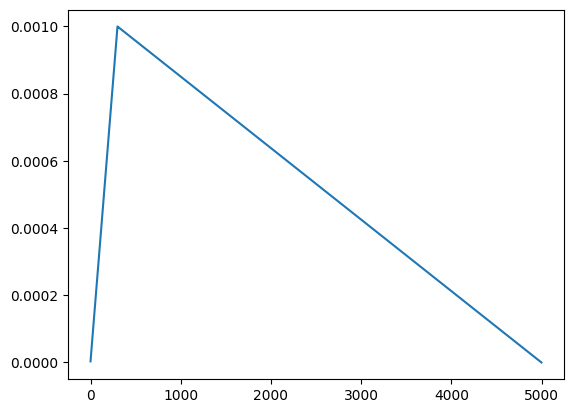

In [61]:
import torch
from torch.optim.lr_scheduler import LambdaLR
from matplotlib import pyplot as plt

def get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps, num_training_steps, last_epoch=-1
):
    """Create a schedule with a learning rate that decreases linearly after
    linearly increasing during a warmup period.

    From:
        https://github.com/uds-lsv/bert-stable-fine-tuning/blob/master/src/transformers/optimization.py
    """

    def lr_lambda(current_step):
        if current_step < num_warmup_steps:
            return float(current_step) / float(max(1, num_warmup_steps))
        return max(
            0.0,
            float(num_training_steps - current_step)
            / float(max(1, num_training_steps - num_warmup_steps)),
        )

    return LambdaLR(optimizer, lr_lambda, last_epoch)
model = torch.nn.Linear(10,10)

optim = torch.optim.AdamW(model.parameters(), lr=1e-3)
lr_sch = get_linear_schedule_with_warmup(optim, 300, 5_000)
lrs = []
for i in range(5000):
    lr_sch.step()
    lrs.append(lr_sch.get_lr()[0])

plt.plot(lrs)
lrs[-2]

0.03125

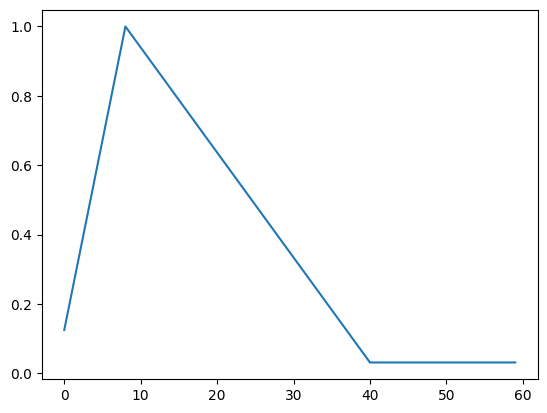

In [ ]:
from optax.schedules import linear_onecycle_schedule

trans_step = 40
schedule = linear_onecycle_schedule(
    transition_steps=trans_step,
    peak_value=1.,
    pct_start=0.2,
    pct_final=1.,
    div_factor=trans_step*0.2,
    final_div_factor=trans_step*(1-0.5))


lrs = np.array([schedule(i) for i in range(60)])
plt.plot(lrs)
lrs[-1]

0.0033333333333333335

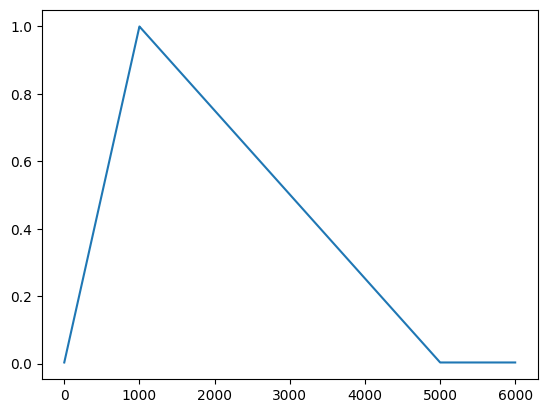

In [65]:
from optax.schedules import linear_onecycle_schedule

trans_step = 5000
schedule = linear_onecycle_schedule(
    transition_steps=trans_step,
    peak_value=1.,
    pct_start=0.2,
    pct_final=1.,
    div_factor=300,
    final_div_factor=300)


lrs = np.array([schedule(i) for i in range(6000)])
plt.plot(lrs)
lrs[-1]

#### continue

In [65]:
print(tokenizer.decode(input_ids[0], skip_special_tokens=True))
print(f"\nDecoded target: {target_id[0]} => {tokenizer.decode(target_id[0], skip_special_tokens=True)}")

Return the label of the correct answer for the question below.

Question: Ian volunteered to eat Dennis's menudo after already having a bowl because _ despised eating intestine.
Choices:
A) Ian
B) Dennis
Answer:

Decoded target: 33 => B


In [66]:
type(model.model.layers[0].self_attn)

transformers.models.qwen2.modeling_qwen2.Qwen2Attention

In [179]:
from torch import nn 

# class ForwardWrapper(nn.Module):
#     def __init__(self, model):
#         super().__init__()
#         self.model = model

#     def forward_wrapper(self, *args, **kwargs):
#         save_['in_args'] = args
#         save_['in_kwargs'] = kwargs
#         return self.model(*args, **kwargs)

save_ = {}
def my_hook(module, in1, in2, in3):
    print(module)
    save_['in2'] = in2
    save_['in1'] = in1
    save_['in3'] = in3

# model.model.layers[0].self_attn = ForwardWrapper(model.model.layers[0].self_attn)

hook_reg = model.model.layers[0].self_attn.register_forward_hook(my_hook, with_kwargs=True)
try:
    with torch.no_grad():
        torch_out = model(input_ids=torch_input_ids, attention_mask=torch_attention_mask)
finally:
    hook_reg.remove()

Qwen2Attention(
  (q_proj): Linear(in_features=896, out_features=896, bias=True)
  (k_proj): Linear(in_features=896, out_features=128, bias=True)
  (v_proj): Linear(in_features=896, out_features=128, bias=True)
  (o_proj): Linear(in_features=896, out_features=896, bias=False)
)


In [194]:
save_['in3'][0][0, 253:260]

tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [-0.0093,  0.0082, -0.0002,  ..., -0.0021, -0.0048,  0.0034],
        [ 0.0094,  0.0002,  0.0060,  ..., -0.0061, -0.0086,  0.0107],
        ...,
        [ 0.0121, -0.0026,  0.0126,  ..., -0.0173, -0.0059,  0.0077],
        [-0.0057,  0.0026,  0.0017,  ..., -0.0049, -0.0058,  0.0156],
        [-0.0120,  0.0034, -0.0035,  ..., -0.0046, -0.0085,  0.0035]],
       device='cuda:0', dtype=torch.float16)

In [67]:
input_ids.shape, attention_mask.shape, labels.shape, target_id.shape

((2556, 300), (2556, 300), (2556,), (2556,))

In [45]:
save_['in3'][0].shape

torch.Size([4, 220, 896])

In [25]:
save_['in2'].keys()

dict_keys(['hidden_states', 'attention_mask', 'position_ids', 'past_key_values', 'use_cache', 'cache_position', 'position_embeddings'])

In [36]:
save_['in2']['position_embeddings'][0].shape

torch.Size([1, 220, 64])

In [49]:
attention_mask[:4].shape

(4, 300)

In [43]:
save_['in2']['hidden_states'].shape

torch.Size([4, 220, 896])

In [ ]:
save_['in2']['attention_mask'][0]

tensor([[[False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         ...,
         [False, False, False,  ...,  True, False, False],
         [False, False, False,  ...,  True,  True, False],
         [False, False, False,  ...,  True,  True,  True]]], device='cuda:0')

#### compare

In [14]:
torch_last
jax_out = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
torch_out = np.take_along_axis(torch_last, all_ids.reshape(1, -1), axis=-1)
print("JAX selected out:", jax_out)
print("Torch selected out:", torch_out)

JAX selected out: [[7.1   9.555]
 [7.13  9.73 ]
 [7.43  9.54 ]
 [7.297 9.664]]
Torch selected out: [[7.094 9.53 ]
 [7.133 9.734]
 [7.45  9.53 ]
 [7.26  9.62 ]]


In [108]:
torch_last
jax_out = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
torch_out = np.take_along_axis(torch_last, all_ids.reshape(1, -1), axis=-1)
print("JAX selected out:", jax_out)
print("Torch selected out:", torch_out)

JAX selected out: [[ 5.887  5.652]
 [10.445  9.234]
 [ 9.36   8.11 ]
 [ 7.477  6.06 ]]
Torch selected out: [[ 8.62   9.96 ]
 [10.164 11.79 ]
 [ 9.03  10.82 ]
 [ 9.15  10.59 ]]


In [106]:
jnp.argmax(attention_mask[:4], axis=-1)

Array([112,  99, 200, 168], dtype=int32)

In [20]:
jnp.broadcast_to(causal_mask, (attention_mask.shape[0], seq_len, seq_len)).shape

(9424, 33, 33)

In [4]:
seq_len = 300
causal_mask = jnp.triu(
                jnp.ones((seq_len, seq_len), dtype=jnp.float16) * -jnp.inf, k=1)
weight = causal_mask + jax.random.normal(key=jax.random.PRNGKey(0), shape=(seq_len, seq_len))
jax.nn.softmax(weight, axis=-1)

Array([[1.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [8.8795382e-01, 1.1204623e-01, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [3.6884800e-01, 1.3232224e-01, 4.9882972e-01, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       ...,
       [4.8701251e-03, 6.8352399e-03, 1.6507380e-02, ..., 2.4016085e-03,
        0.0000000e+00, 0.0000000e+00],
       [1.7637190e-03, 1.3910775e-04, 3.2012344e-03, ..., 2.1198380e-03,
        4.8052880e-04, 0.0000000e+00],
       [1.5128745e-02, 5.9490833e-03, 7.3946971e-03, ..., 2.0531041e-04,
        1.1541211e-03, 3.3987311e-03]], dtype=float32)

In [5]:
causal_mask

Array([[  0., -inf, -inf, ..., -inf, -inf, -inf],
       [  0.,   0., -inf, ..., -inf, -inf, -inf],
       [  0.,   0.,   0., ..., -inf, -inf, -inf],
       ...,
       [  0.,   0.,   0., ...,   0., -inf, -inf],
       [  0.,   0.,   0., ...,   0.,   0., -inf],
       [  0.,   0.,   0., ...,   0.,   0.,   0.]], dtype=float16)

In [6]:
weight = jax.random.normal(key=jax.random.PRNGKey(0), shape=(4, 10, seq_len, seq_len))

In [12]:
attention_mask

Array([[0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       ...,
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1]], dtype=int32)

In [15]:

mask = (attention_mask[:4, None, None, :] == 0)
attn_weights2 = jnp.where(mask, -jnp.inf,  weight)
attn_weights2

Array([[[[       -inf,        -inf,        -inf, ..., -0.7116935 ,
          -0.05395174, -2.0926828 ],
         [       -inf,        -inf,        -inf, ..., -0.50935936,
           1.0135212 ,  0.60979146],
         [       -inf,        -inf,        -inf, ...,  1.2272704 ,
          -1.3195466 , -0.32613733],
         ...,
         [       -inf,        -inf,        -inf, ...,  0.12316248,
           0.8117914 , -0.1125572 ],
         [       -inf,        -inf,        -inf, ...,  0.03323483,
          -1.4509728 , -0.11996239],
         [       -inf,        -inf,        -inf, ..., -2.0630805 ,
          -0.33650947,  0.7435536 ]],

        [[       -inf,        -inf,        -inf, ..., -1.3711846 ,
           1.5841771 , -1.0049901 ],
         [       -inf,        -inf,        -inf, ..., -0.00536305,
           0.9028315 ,  1.4512507 ],
         [       -inf,        -inf,        -inf, ...,  1.1094759 ,
          -0.41762683, -0.11658346],
         ...,
         [       -inf,        -inf

In [18]:

attn_weights = jnp.where(attention_mask[:4, None, None, :], weight, -jnp.inf)
attn_weights[0,0]

Array([[       -inf,        -inf,        -inf, ..., -0.7116935 ,
        -0.05395174, -2.0926828 ],
       [       -inf,        -inf,        -inf, ..., -0.50935936,
         1.0135212 ,  0.60979146],
       [       -inf,        -inf,        -inf, ...,  1.2272704 ,
        -1.3195466 , -0.32613733],
       ...,
       [       -inf,        -inf,        -inf, ...,  0.12316248,
         0.8117914 , -0.1125572 ],
       [       -inf,        -inf,        -inf, ...,  0.03323483,
        -1.4509728 , -0.11996239],
       [       -inf,        -inf,        -inf, ..., -2.0630805 ,
        -0.33650947,  0.7435536 ]], dtype=float32)

In [20]:
weight[0,0]

Array([[ 1.6226422 ,  2.0252647 , -0.43359444, ..., -0.7116935 ,
        -0.05395174, -2.0926828 ],
       [ 0.47375467, -1.5962535 , -0.15396847, ..., -0.50935936,
         1.0135212 ,  0.60979146],
       [ 0.399992  , -0.62515265,  0.7018721 , ...,  1.2272704 ,
        -1.3195466 , -0.32613733],
       ...,
       [ 0.8301435 ,  1.1691153 ,  2.0508313 , ...,  0.12316248,
         0.8117914 , -0.1125572 ],
       [-0.15068035, -2.6906116 ,  0.44543153, ...,  0.03323483,
        -1.4509728 , -0.11996239],
       [ 2.236748  ,  1.3033886 ,  1.5209146 , ..., -2.0630805 ,
        -0.33650947,  0.7435536 ]], dtype=float32)

In [17]:
jnp.allclose(attn_weights, attn_weights2)

Array(True, dtype=bool)

In [38]:
causal_mask = causal_mask.at[:, attention_mask[0] == 0].set(-np.inf)
causal_mask

Array([[-inf, -inf, -inf, ..., -inf, -inf, -inf],
       [-inf, -inf, -inf, ..., -inf, -inf, -inf],
       [-inf, -inf, -inf, ..., -inf, -inf, -inf],
       ...,
       [-inf, -inf, -inf, ...,   0., -inf, -inf],
       [-inf, -inf, -inf, ...,   0.,   0., -inf],
       [-inf, -inf, -inf, ...,   0.,   0.,   0.]], dtype=float16)

In [33]:
causal_mask

Array([[  0., -inf, -inf, ..., -inf, -inf, -inf],
       [  0.,   0., -inf, ..., -inf, -inf, -inf],
       [  0.,   0.,   0., ..., -inf, -inf, -inf],
       ...,
       [  0.,   0.,   0., ...,   0., -inf, -inf],
       [  0.,   0.,   0., ...,   0.,   0., -inf],
       [  0.,   0.,   0., ...,   0.,   0.,   0.]], dtype=float16)

In [ ]:
selected = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
selected

Array([[ 5.887,  5.652],
       [10.445,  9.234],
       [ 9.36 ,  8.11 ],
       [ 7.477,  6.06 ]], dtype=float16)

### with subspace model wrapper

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".99"




In [2]:
import torch
from transformers import AutoTokenizer
from transformers import AutoModelForCausalLM

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

Target Device: cuda


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [4]:
import jax
import jax.numpy as jnp
from qwen_fineTuning_PtoC import QwenTextClassificationWrapper
import numpy as np
from flax.core import freeze, unfreeze

%load_ext autoreload
%autoreload 2

# with np.load("datasets/text_classification/boolq/train_data.npz") as data:
# with np.load("datasets/text_classification/winogrande_s/test_data.npz") as data:
with np.load("artifacts/winogrande_s_dataset:v0/test_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])
    all_target_ids = jnp.array(data['target_ids'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape, all_target_ids.shape

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


((1200, 64), (1200, 64), (1200,), (1200,), (2, 1))

In [8]:

model = QwenTextClassificationWrapper("artifacts/qwen2.5_7B_bfloat16:v0/", target_token_ids=all_target_ids)

params = model.init(None, None)
params = unfreeze(params)
params

{'params': {'embed_tokens': {'embedding': Array([[-0.0151978, -0.00387573, 0.0145264, ..., 0.0111084, 0.0419922,
           -0.0177002],
          [0.0149536, 0.0149536, 0.017334, ..., -0.0194092, 0.0167236,
           0.0078125],
          [-0.00878906, -0.00488281, 0.00405884, ..., -0.000595093,
           -0.0283203, 0.00799561],
          ...,
          [-1.17549e-37, 1.17549e-37, 1.17549e-37, ..., -1.17549e-37,
           1.17549e-37, 1.17549e-37],
          [1.17549e-37, -1.17549e-37, 1.17549e-37, ..., -1.17549e-37,
           1.17549e-37, -1.17549e-37],
          [1.17549e-37, -1.17549e-37, -1.17549e-37, ..., 1.17549e-37,
           1.17549e-37, -1.17549e-37]], dtype=bfloat16)},
  'layers_0': {'input_layernorm': {'weight': Array([0.271484, 0.294922, 0.255859, ..., 0.28125, 0.255859, 0.277344],      dtype=bfloat16)},
   'mlp': {'down_proj': {'kernel': Array([[0.000495911, 0.00817871, -0.00939941, ..., 0.0177002, 0.0336914,
             0.0180664],
            [0.0123901, 0.027832

In [5]:
logits = model.apply(params, input_ids[:6], attention_mask[:6], train=False)
logits

Array([[6.71875, 8.625],
       [6.65625, 8.5625],
       [5.78125, 9.5],
       [6.25, 9.6875],
       [6.53125, 9.25],
       [6.25, 9.5]], dtype=bfloat16)

In [6]:
print(tokenizer.decode(input_ids[1138], skip_special_tokens=True))

Return the label of the correct answer for the question below.

Question: Katrina did not value the antique pictures as much as Lindsey because _ was a history buff.
Choices:
A) Katrina
B) Lindsey
Answer:


In [ ]:
from src.subspace_curve import CategorySubspace, filter_mask, LoRACategorySubspace

key = jax.random.PRNGKey(0)
s_model = CategorySubspace(model, k=2)

curve_mask = jax.tree.map(lambda x: False, params)['params']
curve_mask = filter_mask(curve_mask, "self_attn", "q_proj", "kernel", as_curve=True)
curve_mask = filter_mask(curve_mask, "self_attn", "v_proj", "kernel", as_curve=True)

train_mask = jax.tree.map(lambda x: False, params['params'])
train_mask = filter_mask(train_mask, "self_attn", "q_proj", "kernel", as_curve=True)
train_mask = filter_mask(train_mask, "self_attn", "v_proj", "kernel", as_curve=True)

s_params = s_model.init_params_from_point(key, params, curve_mask, noise_fn=lambda p, key: p)
del params
s_model.set_train_mask(train_mask)
s_model(s_params['params'], {}, 0.5, (input_ids[:12], attention_mask[:12]), train=False)


In [5]:
# with lora
from src.subspace_curve import CategorySubspace, filter_mask, LoRACategorySubspace

lora_mask = jax.tree.map(lambda x: False, params)['params']
lora_mask = filter_mask(lora_mask, "self_attn", "q_proj", "kernel", as_curve=np.array([1,0]))
lora_mask = filter_mask(lora_mask, "self_attn", "v_proj", "kernel", as_curve=np.array([1,0]))

key = jax.random.PRNGKey(0)
s_model = LoRACategorySubspace(model=model, k=2, lora_mask=lora_mask, r=8, lora_dtype='float32', lora_alpha=16.)

curve_mask = jax.tree.map(lambda x: False, params)['params']
curve_mask = filter_mask(curve_mask, "self_attn", "q_proj", "kernel", as_curve=True)
curve_mask = filter_mask(curve_mask, "self_attn", "v_proj", "kernel", as_curve=True)

train_mask = jax.tree.map(lambda x: False, params['params'])
train_mask = filter_mask(train_mask, "self_attn", "q_proj", "kernel", as_curve=True)
train_mask = filter_mask(train_mask, "self_attn", "v_proj", "kernel", as_curve=True)

s_params = s_model.init_params_from_point(key, params, curve_mask, noise_fn=lambda p, key: p)
del params

s_model.set_train_mask(train_mask)
s_model(s_params['params'], {}, 0.5, (input_ids[:12], attention_mask[:12]), train=False)

(Array([[ 6.53125,  8.375  ],
        [ 6.53125,  8.375  ],
        [ 5.78125,  9.5625 ],
        [ 6.46875,  9.875  ],
        [ 6.625  ,  9.3125 ],
        [ 6.15625,  9.3125 ],
        [ 7.375  , 10.875  ],
        [ 7.375  , 10.4375 ],
        [ 6.53125,  8.6875 ],
        [ 6.09375, 10.375  ],
        [ 6.03125, 10.25   ],
        [ 7.3125 ,  9.5625 ]], dtype=float32),
 {})

In [14]:
s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].shape

{'A': (3, 8, 896), 'B': (896, 8), 'w0': (896, 896)}

In [15]:
s_params['params']['layers_0']['self_attn']['v_proj']['kernel'].shape

{'A': (3, 8, 896), 'B': (128, 8), 'w0': (896, 128)}

In [16]:
print(s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].A.dtype)
print(s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].B.dtype)
print(s_params['params']['layers_0']['self_attn']['q_proj']['kernel'].w0.dtype)

float32
float32
bfloat16


In [17]:
from qwen_fineTuning_PtoC import setup_metrics

metrics = setup_metrics(s_model, 4, input_ids[:12], attention_mask[:12], labels[:12], 1, use_linspace=True, average=True)
metrics(key, s_params)

{'loss': Array(1.63281, dtype=bfloat16),
 'acc': Array(0.5, dtype=float32),
 'ece': Array(0.4733073, dtype=float32)}

In [70]:
from optax import adamw


optimizer = adamw(1e-5)
trainable_params = s_model.only_trainable_params(s_params['params'])
opt_state = optimizer.init(trainable_params)

In [ ]:
sub_key = jax.random.PRNGKey(1)

t = random.uniform(sub_key, (1,), minval=0., maxval=1.)
loss, params, opt_state, grad_ = s_model.train_step(
                    sub_key, t, params, (input_ids[:4], attention_mask[:4]), labels[:4], opt_state, optimizer)
loss

Array(1.82812, dtype=bfloat16)

## Load model and data from wandb

In [2]:
from qwen_fineTuning_PtoC import load_text_classification_data, QwenTextClassificationWrapper
import wandb
from copy import deepcopy
from flax.core import freeze, unfreeze
from src.subspace_curve import filter_mask, LoRACategorySubspace
import jax
import numpy as np
import jax.numpy as jnp
from qwen_fineTuning_PtoC import setup_metrics
from numpyro.distributions import Categorical
import pandas as pd
import seaborn as sns
import numpy as np

import matplotlib.pyplot as plt
import os


os.environ["CUDA_VISIBLE_DEVICES"] = "0"



%load_ext autoreload
%autoreload 2


api = wandb.Api()
run = api.run("ddold/qwen_PtoC/h97far1q")

config = deepcopy(run.config)

# config['dataset_path'] = "artifacts/winogrande_s_dataset:v0/test_data.npz"
config['dataset_path'] = "artifacts/obqa_dataset:v0/test_data.npz"
config['net_kwargs'] = {
    'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
}

# run = wandb.init(project="qwen_PtoC", name="test_prediction")
test_input_ids, test_attention_mask, test_labels, test_target_ids, test_unique_target_ids = load_text_classification_data(config['dataset_path'], run=None)
key = jax.random.PRNGKey(config.get('rng_seed', 0))

test_input_ids.shape, test_attention_mask.shape, test_labels.shape, test_target_ids.shape, test_unique_target_ids.shape


((500, 127), (500, 127), (500,), (500,), (4, 1))

In [3]:
def init_model(config, test_unique_target_ids):
    # initialize curve model
    if config['net_kwargs']['model_path'].startswith('ddold/'):
        model_artifact = run.use_artifact(config['net_kwargs']['model_path'], type='model')
        config['net_kwargs']['model_path'] = model_artifact.download()
    model = QwenTextClassificationWrapper(**config['net_kwargs'], target_token_ids=test_unique_target_ids)
    params = unfreeze(model.init(None, None))

    curve_mask = jax.tree.map(lambda x: False, params['params'])
    # only if k > 0, otherwise no curve parameters are used
    if config['curve_params']['k'] > 0:
        for f in config['curve_params']['filter_masks']:
            curve_mask = filter_mask(curve_mask, *f['keys'], as_curve=True, BoolschenOperator=eval(f['op']))

    optimizer_conf = config['curve_params']['optimizer_conf']
    lora_params = config.get('lora_params', None)
    filter_masks = config['curve_params']['filter_masks']
    if "freeze_other_params" in optimizer_conf and optimizer_conf["freeze_other_params"]:
        train_mask = jax.tree.map(lambda x: False, params['params'])
        # all curve and lora params are trainable
        for f in filter_masks:
            train_mask = filter_mask(train_mask, *f['keys'], as_curve=True, BoolschenOperator=eval(f['op']))
        if lora_params and lora_params['use_lora']:
            for f in lora_params['filter_masks']:
                train_mask = filter_mask(train_mask, *f['keys'], as_curve=True, BoolschenOperator=eval(f['op']))
    else:
        train_mask = jax.tree.map(lambda x: True, params['params'])

    lora_mask = jax.tree.map(lambda x: False, params['params'])  # LoRA mask for all parameters
    if lora_params and lora_params['use_lora']:
        for f in lora_params['filter_masks']:
            lora_mask = filter_mask(lora_mask, *f['keys'], as_curve=np.array(f['dims']), BoolschenOperator=eval(f['op']))

    s_model = LoRACategorySubspace(lora_mask=lora_mask, r=lora_params['r'], lora_dtype=lora_params['lora_dtype'], lora_alpha=lora_params['lora_alpha'], lora_mode=lora_params.get('lora_mode', 'A(t)B'), 
                                    model=model, k=config['curve_params']['k'], weight_decay=config['curve_params']['weight_decay'],
                                    perm_spec=False,
                                    natural_parameterization=config['curve_params']['natural_parameterization'],
                                    mutuable_param_name=False)


    # initialize curve parameter with pretrained point parameter
    init_key = jax.random.PRNGKey(config.get('rng_seed', 1))
    params = s_model.init_params_from_point(init_key, params, curve_mask, noise_fn=lambda p, key: p+config['curve_params']['jitter_multiplier']*jax.random.normal(key, p.shape, dtype=p.dtype))

    if lora_params and lora_params['use_lora']:
        train_mask = s_model.update_mask_for_lora(train_mask, params['params'], b_off=False, w0_off=True) # w0 must be off for LoRA
    s_model.set_train_mask(train_mask)
    return s_model, params

# s_model, params = init_model(config)

In [4]:
# load trainable params from checkpoint

def load_checkpoint(run, params, s_model):
    ''' Load trainable parameters from a wandb run artifact into the model parameters.
        Args:
            run: wandb run object containing the artifacts.
            params: current model parameters (flax format).
        Returns:
            params: updated model parameters with loaded trainable parameters.
    '''
    def load_art(load_run):
        artifact_use, artifact_weights_use = False, False
        print(f"Found config with obqa dataset with name: {load_run.name}, id: {load_run.id}")
        for art_l in load_run.logged_artifacts():
            if art_l.type == "pytree" and art_l.name.startswith("params"):
                print(f"Downloading params from {art_l.name}")
                # artifact_use = logger.use_artifact(art_l, type='pytree')
                artifact_use = art_l
            if art_l.type == "npz" and art_l.name.startswith("bma_weights"):
                print(f"Downloading weights from {art_l.name}")
                # artifact_weights_use = logger.use_artifact(art_l, type='npz')
                artifact_weights_use = art_l
        return artifact_use, artifact_weights_use

    artifact_use, artifact_weights_use = load_art(run)


    trainable_params = False
    # # load trainable params
    for f in artifact_use.files():
        if 'trainable_params' in f.name:
            trainable_params = np.load(artifact_use.get_entry(f.name).download(), allow_pickle=True).item()
            print(f"Loaded trainable_params from {f.name}")
            assert len(set(trainable_params.keys()) - set(params['params'].keys())) == 0, "Loaded trainable_params do not match model params"
    assert trainable_params, f"trainable_params not found in artifact {artifact_use.name}"

    # merge loaded trainable params with current params
    def load_fn(m, p, pl):
        if m:
            assert p.shape == pl.shape, f"Shape mismatch for parameter with shape {p.shape} and loaded shape {pl.shape}"
            return pl
        else:
            return p
    params['params'] = jax.tree.map(load_fn, s_model.train_mask, params['params'], trainable_params)

    bma_weights = False
    # # load bma weights
    for f in artifact_weights_use.files():
        if 'weights' in f.name:
            bma_weights = np.load(artifact_weights_use.get_entry(f.name).download(), allow_pickle=True)
            print(f"Loaded bma_weights from {f.name}")
    return params, bma_weights

# load_run = api.run("ddold/qwen_PtoC/h97far1q")
# params = load_checkpoint(load_run, params)

#### Single nll test

test nll variing accross t-space

In [ ]:
s_model, params = init_model(config, test_unique_target_ids)
load_run = api.run("ddold/qwen_PtoC/h97far1q")
params, _ = load_checkpoint(load_run, params, s_model)

KeyError: 'lora_mode'

In [ ]:

t_space = jnp.linspace(0., 1., 5)
rng_key, key = jax.random.split(key)
test_metrics_fn_final = setup_metrics(s_model, 16, test_input_ids, test_attention_mask, test_labels, n_samples=len(t_space), use_linspace=True, average=False, key_prefix='final_')
curve_metric, logits_test = test_metrics_fn_final(rng_key, params) # logits test with shape (n_samples, n_data, n_classes)
curve_metric

{'final_loss': Array([2.5908036, 2.198025 , 2.1376307, 2.129743 , 2.3529203], dtype=float32),
 'final_acc': Array([0.6658333 , 0.65749997, 0.65666664, 0.6583333 , 0.64666665],      dtype=float32),
 'final_ece': Array([0.3010788 , 0.28424135, 0.2872062 , 0.28886086, 0.30400172],      dtype=float32)}

In [14]:
curve_metric

{'final_loss': Array([2.5908036, 2.198025 , 2.1376307, 2.129743 , 2.3529203], dtype=float32),
 'final_acc': Array([0.6658333 , 0.65749997, 0.65666664, 0.6583333 , 0.64666665],      dtype=float32),
 'final_ece': Array([0.3010788 , 0.28424135, 0.2872062 , 0.28886086, 0.30400172],      dtype=float32)}

In [15]:
jax.tree.map(lambda x: x.mean(), curve_metric)

{'final_acc': Array(0.657, dtype=float32),
 'final_ece': Array(0.2930778, dtype=float32),
 'final_loss': Array(2.2818246, dtype=float32)}

In [16]:
from numpyro.distributions import Categorical
nll = -Categorical(logits=logits_test).log_prob(test_labels[None, :])
nll.shape

(5, 1200)

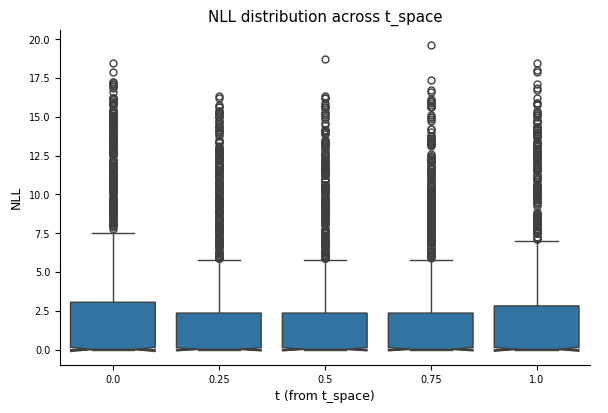

In [17]:
import pandas as pd
import seaborn as sns
import numpy as np

import matplotlib.pyplot as plt

# convert jax arrays to numpy
t_vals = np.array(t_space).reshape(-1)
nll_arr = np.array(nll)  # shape (n_t, n_samples)

# build dataframe: one row per (t, sample_nll)
df = pd.DataFrame({
    "t": np.repeat(t_vals, nll_arr.shape[1]),
    "nll": nll_arr.flatten()
})

# boxplot with seaborn.catplot
sns.catplot(data=df, x="t", y="nll", kind="box", height=4, aspect=1.5, notch=True)
plt.xlabel("t (from t_space)")
plt.ylabel("NLL")
plt.title("NLL distribution across t_space")
plt.show()

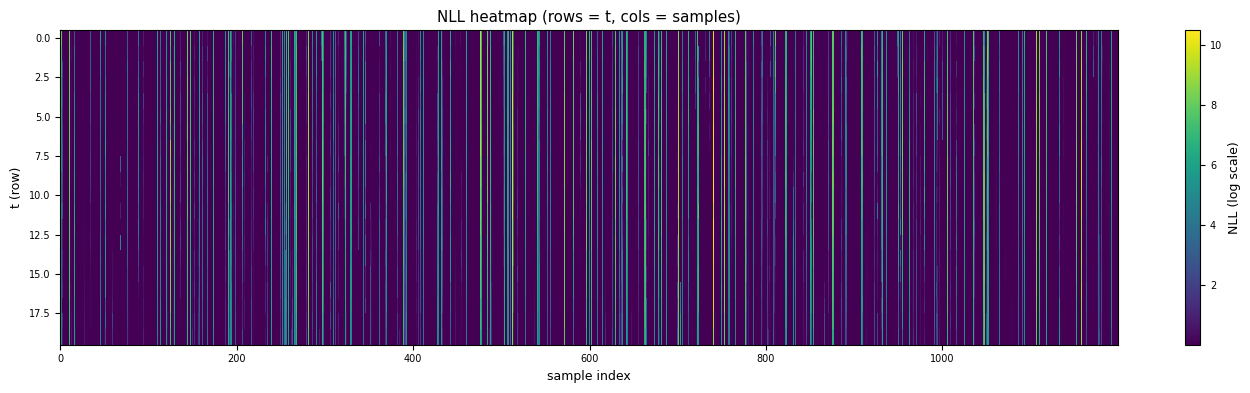

In [ ]:
from matplotlib.colors import LogNorm, Normalize


plt.figure(figsize=(14, 4))
# convert to numpy and ensure positive values for log scaling
data = np.array(nll)
eps = 1e-6
data = np.where(data <= 0, eps, data)

# norm = LogNorm(vmin=data.min(), vmax=data.max())
norm = Normalize(vmin=data.min(), vmax=data.max())
im = plt.imshow(data, aspect='auto', cmap='viridis', norm=norm, interpolation='nearest')
plt.colorbar(im, label='NLL (log scale)')
plt.xlabel('sample index')
plt.ylabel('t (row)')
plt.title('NLL heatmap (rows = t, cols = samples)')
plt.tight_layout()
plt.show()

#### NLL analyse per dataset

In [ ]:
test_ids = ['oe79hwp5', 'r1mc5ewx', 'y7w5m8af', 'v74gcy9j', '2xgtqyg1', 'bpwgok1f',]

api = wandb.Api()
# run = api.run(f"ddold/qwen_PtoC/{test_ids[0]}")
# config = deepcopy(run.config)
# config['net_kwargs'] = {
#     'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
# }
# s_model, params = init_model(config)

nlls = []
df = []
logits = {}

for test_id in test_ids:

    run = api.run(f"ddold/qwen_PtoC/{test_id}")

    config = deepcopy(run.config)
    # config['dataset_path'] = "artifacts/winogrande_s_dataset:v0/test_data.npz"
    ds_name = config['dataset_path'].split("/")[-1]
    print(f"Dataset name: {ds_name}")
    config['dataset_path'] = f"artifacts/{ds_name}/test_data.npz"
    config['net_kwargs'] = {
        'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
    }

    # run = wandb.init(project="qwen_PtoC", name="test_prediction")
    test_input_ids, test_attention_mask, test_labels, test_target_ids, test_unique_target_ids = load_text_classification_data(config['dataset_path'], run=None)
    key = jax.random.PRNGKey(config.get('rng_seed', 0))

    print(test_input_ids.shape, test_attention_mask.shape, test_labels.shape, test_target_ids.shape, test_unique_target_ids.shape)
    # test_input_ids = test_input_ids[:128]
    # test_attention_mask = test_attention_mask[:128]
    # test_labels = test_labels[:128]

    s_model, params = init_model(config, test_unique_target_ids)
    params, _ = load_checkpoint(run, params, s_model)

    t_space = jnp.linspace(0., 1., 20)
    rng_key, key = jax.random.split(key)
    test_metrics_fn_final = setup_metrics(s_model, 32, test_input_ids, test_attention_mask, test_labels, n_samples=len(t_space), use_linspace=True, average=False, key_prefix='final_')
    curve_metric, logits_test = test_metrics_fn_final(rng_key, params) # logits test with shape (n_samples, n_data, n_classes)
    print(jax.tree.map(lambda x: x.mean(), curve_metric))
    logits[ds_name] = dict(logit=logits_test, labels=test_labels)

    # compute NLL
    nll = -Categorical(logits=logits_test).log_prob(test_labels[None, :])
    nlls.append(nll)

    # convert jax arrays to numpy
    t_vals = np.array(t_space).reshape(-1)
    nll_arr = np.array(nll)  # shape (n_t, n_samples)

    # build dataframe: one row per (t, sample_nll)
    df.append(pd.DataFrame({
        "t": np.repeat(t_vals, nll_arr.shape[1]),
        "nll": nll_arr.flatten(),
        "dataset": ds_name,
    }))
df = pd.concat(df, ignore_index=True)

# boxplot with seaborn.catplot
sns.catplot(data=df, col="dataset", x="t", y="nll", kind="box", height=4, aspect=.8, notch=True, col_wrap=3)
plt.tight_layout()
jnp.savez("test_logits.npz", **logits)


Dataset name: ARC-Easy_dataset:v0
(500, 194) (500, 194) (500,) (500,) (5, 1)
Found config with obqa dataset with name: upbeat-sweep-45, id: oe79hwp5
Loaded trainable_params from oe79hwp5_trainable_params.npy
Loaded bma_weights from oe79hwp5_weights.npz


In [108]:
logits_load = dict(np.load('test_logits.npz', allow_pickle=True))

df = []
t_space = jnp.linspace(0., 1., 20)

for ds, data in logits_load.items():
    try:
        logit = data.item()['logit']
        labels = data.item()['labels']
    except:
        logit = data['logit']
        labels = data['labels']
    
    nll = -Categorical(logits=logit).log_prob(labels[None, :])
    print(f"NLL mean: {nll.mean():.2f} \t Dataset: {ds}, NLL shape: {nll.shape},")
    # build dataframe: one row per (t, sample_nll)

    t_vals = np.array(t_space).reshape(-1)
    nll_arr = np.array(nll)  # shape (n_t, n_samples)
    df.append(pd.DataFrame({
        "t": np.repeat(t_vals, nll_arr.shape[1]),
        "nll": nll_arr.flatten(),
        "dataset": ds_name,
    }))

df = pd.concat(df, ignore_index=True)

    # same result with optax
    # nll = optax.losses.softmax_cross_entropy_with_integer_labels(
    #             logits=logit, labels=labels[None, :])
    # print(f"NLL mean: {nll.mean():.2f} \t Dataset: {ds}, NLL shape: {nll.shape},")
df['dataset'].unique()

NLL mean: 0.34 	 Dataset: ARC-Easy_dataset:v0, NLL shape: (20, 500),
NLL mean: 0.69 	 Dataset: ARC-Challenge_dataset:v0, NLL shape: (20, 200),
NLL mean: 0.42 	 Dataset: obqa_dataset:v0, NLL shape: (20, 500),
NLL mean: 0.28 	 Dataset: boolq_dataset:v0, NLL shape: (20, 3200),
NLL mean: 2.00 	 Dataset: winogrande_s_dataset:v0, NLL shape: (20, 1200),
NLL mean: 0.89 	 Dataset: winogrande_m_dataset:v0, NLL shape: (20, 1200),


array(['ARC-Easy_dataset:v0'], dtype=object)

1. Average over probabilities with samples (BMA)

    $p(y \mid x,D) = \frac{1}{S} \sum^S_{s=1} p(y \mid x, t_s)$

    Code: log_predict = jax.nn.logsumexp(logit, axis=0) - jnp.log(logit.shape[0])

2. Compute performance or do temperature scaling

    $nll = - \frac{1}{N} \sum^N_{i=1}\text{log} \frac{ p(y \mid x,D)^{1/T}}{\sum_{c=1} p(y \mid x,D)^{1/T}}$

    Code: nll = -Categorical(logits=log_predict/temp).log_prob(labels)

In [ ]:
# save dataframe as parquet
try:
    df.to_parquet("nll_across_datasets.parquet", index=False)
    print("Saved to nll_across_datasets.parquet")
except Exception as e:
    print("Failed to save parquet:", e)
    print("Install pyarrow or fastparquet (e.g. pip install pyarrow) and retry.")

Saved to nll_across_datasets.parquet


In [ ]:
df = pd.read_parquet("nll_across_datasets.parquet")
df

,t,nll,dataset
0,0.0,0.000069,ARC-Easy_dataset:v0
1,0.0,0.000004,ARC-Easy_dataset:v0
2,0.0,-0.000000,ARC-Easy_dataset:v0
3,0.0,-0.000000,ARC-Easy_dataset:v0
4,0.0,-0.000000,ARC-Easy_dataset:v0
...,...,...,...
135995,1.0,0.000805,winogrande_m_dataset:v0
135996,1.0,0.012510,winogrande_m_dataset:v0
135997,1.0,0.005234,winogrande_m_dataset:v0
135998,1.0,0.026300,winogrande_m_dataset:v0


dataset = ARC-Easy_dataset:v0
dataset = ARC-Challenge_dataset:v0
dataset = obqa_dataset:v0
dataset = boolq_dataset:v0
dataset = winogrande_s_dataset:v0
dataset = winogrande_m_dataset:v0


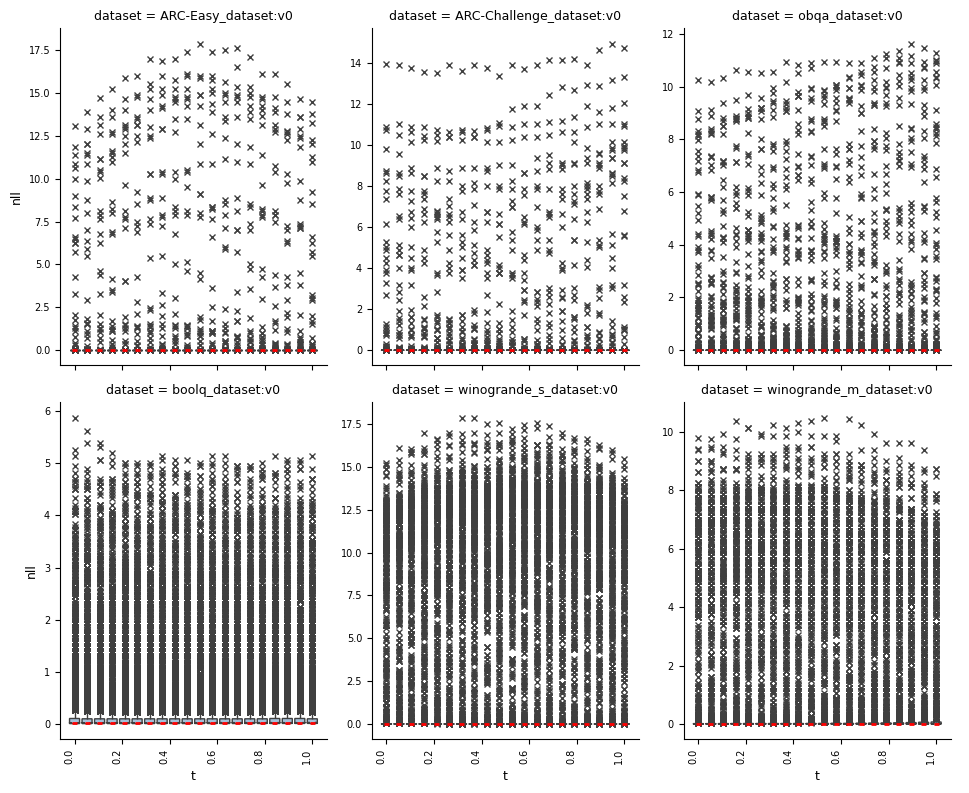

In [7]:
# boxplot with seaborn.catplot
kwargs = dict( showcaps=False,
    notch=True,
    flierprops={"marker": "x"},
    boxprops={"facecolor": (.3, .5, .7, .5)},
    medianprops={"color": "r", "linewidth": 2},
)
g = sns.catplot(data=df, col="dataset", x="t", y="nll", kind="box", height=4, aspect=.8, col_wrap=3, sharey=False, native_scale=True, **kwargs)

dg = df.groupby('dataset')

for ax in g.axes.flat:
    print(ax.get_title())
    group = dg.get_group(ax.get_title().split(' = ')[1])
    iqr = group.groupby('t')['nll'].quantile(0.75).max() - group.groupby('t')['nll'].quantile(0.25).min()
    y_max = group.groupby('t')['nll'].quantile(0.75).max() + 1.5 * iqr
    # ax.set_ylim(0, y_max * 1.05)  # Add 5% padding
    plt.setp(ax.get_xticklabels(), rotation=90, ha='right')
    # ax.xaxis.set_major_formatter(formatter)

plt.tight_layout()


dataset = ARC-Easy_dataset:v0
dataset = ARC-Challenge_dataset:v0
dataset = obqa_dataset:v0
dataset = boolq_dataset:v0
dataset = winogrande_s_dataset:v0
dataset = winogrande_m_dataset:v0


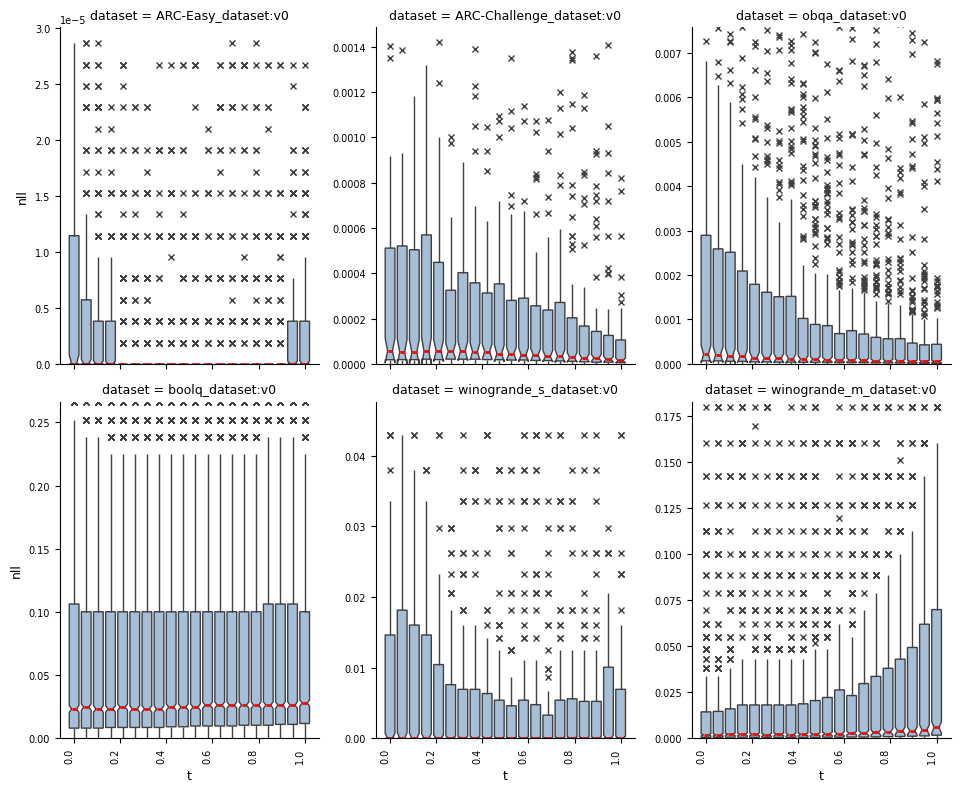

In [8]:
# fig, axes = plt.subplots(2, 3, figsize=(18, 10))
# axes = axes.flatten()
# df = []
# for nll, ds_name in zip(nlls, test_ids):

#     # convert jax arrays to numpy
#     t_vals = np.array(t_space).reshape(-1)
#     nll_arr = np.array(nll)  # shape (n_t, n_samples)

#     # build dataframe: one row per (t, sample_nll)
#     df.append(pd.DataFrame({
#         "t": np.repeat(t_vals, nll_arr.shape[1]),
#         "nll": nll_arr.flatten(),
#         "dataset": ds_name,
#     }))
# df = pd.concat(df, ignore_index=True)

# boxplot with seaborn.catplot
kwargs = dict( showcaps=False,
    notch=True,
    flierprops={"marker": "x"},
    boxprops={"facecolor": (.3, .5, .7, .5)},
    medianprops={"color": "r", "linewidth": 2},
)
g = sns.catplot(data=df, col="dataset", x="t", y="nll", kind="box", height=4, aspect=.8, col_wrap=3, sharey=False, native_scale=True, **kwargs)

dg = df.groupby('dataset')
# Set y-axis limits to max whisker length for each subplot
# import matplotlib.ticker as ticker
# formatter = ticker.StrMethodFormatter('{x:.2f}')

for ax in g.axes.flat:
    print(ax.get_title())
    group = dg.get_group(ax.get_title().split(' = ')[1])
    iqr = group.groupby('t')['nll'].quantile(0.75).max() - group.groupby('t')['nll'].quantile(0.25).min()
    y_max = group.groupby('t')['nll'].quantile(0.75).max() + 1.5 * iqr
    ax.set_ylim(0, y_max * 1.05)  # Add 5% padding
    plt.setp(ax.get_xticklabels(), rotation=90, ha='right')
    # ax.xaxis.set_major_formatter(formatter)

plt.tight_layout()


##### post-hoc temperature calibration

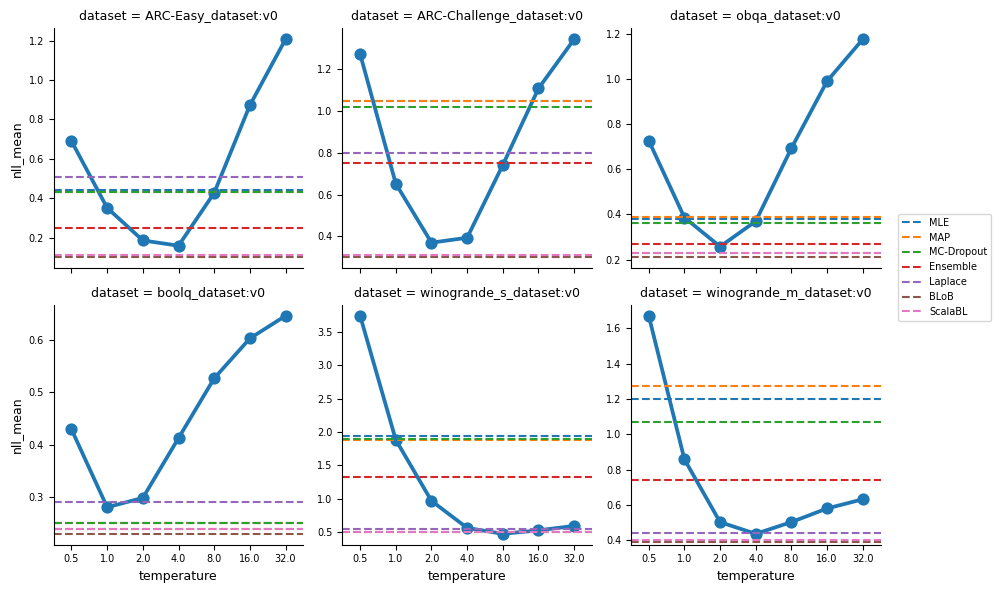

In [106]:
temperatures = [0.5, 1.0, 2.0, 4.0, 8.0, 16.0, 32.]
nll_temp = []

for ds, data in logits_load.items():
    for temp in temperatures:
        logit = data.item()['logit']
        labels = data.item()['labels']
        # first apply temperature scaling, then average over t samples to get mean logits
        # compute averaged log probabilities
        log_predict = jax.nn.logsumexp(logit, axis=0) - jnp.log(logit.shape[0])
        nll = -Categorical(logits=log_predict/temp).log_prob(labels)
        nll_temp.append(pd.Series([ds, temp, nll.mean().item(), "v4"], index=['dataset', 'temperature', 'nll_mean', 'version']))

nll_temp = pd.concat(nll_temp, axis=1).T
g = sns.catplot(data=nll_temp, x="temperature", y="nll_mean", col="dataset", kind="point", height=3, aspect=1., sharey=False, col_wrap=3)

ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}
for ax in g.axes.flatten():
    ds_n = ax.get_title().split(' = ')[1]
    ds_n = ds_n.replace('_dataset:v0', '')
    for i, (method, ref) in enumerate(ref_nll[ds_n].items()):
        ax.axhline(ref, ls='--', label=method, color=plt.cm.tab10(i))
    # ax.legend()

ax.legend(bbox_to_anchor=(1.05, 1.4), loc='upper left')


In [9]:
# 50% => median NLL per dataset and average across t
# mean => average NLL per dataset and average across t
df.groupby(['dataset', 't']).describe(percentiles=[0.1, 0.5, 0.95, 0.99, 0.999])['nll'].reset_index().groupby('dataset').mean()

,t,count,mean,std,min,10%,50%,95%,99%,99.9%,max
dataset,,,,,,,,,,,
ARC-Challenge_dataset:v0,0.5,200.0,0.685382,2.280066,0.000000,7.028580e-06,0.000043,6.399268,10.997826,13.510393,13.959378
ARC-Easy_dataset:v0,0.5,500.0,0.343194,1.936783,0.000000,0.000000e+00,0.000000,0.054337,12.992625,15.438788,16.068785
boolq_dataset:v0,0.5,3200.0,0.282941,0.725615,0.000173,4.546781e-03,0.025074,2.018194,3.712567,4.810169,5.146592
obqa_dataset:v0,0.5,500.0,0.420172,1.617722,0.000002,1.476288e-05,0.000112,3.089315,9.384598,10.542979,10.864163
winogrande_m_dataset:v0,0.5,1200.0,0.887952,2.081882,0.000017,2.717400e-04,0.002847,6.455587,7.891489,9.422945,9.950053
winogrande_s_dataset:v0,0.5,1200.0,2.000935,4.246620,0.000000,1.907349e-07,0.000007,12.610785,14.366500,16.342275,16.821875


##### ScalaBL analyse

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
from numpyro.distributions import Categorical
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
 
file = np.load("../BayesAdapt/scalaBl_winogrande_s_0.npz")
logits_scala, labels_scala = file['logits'], file['labels']
logits_scala = logits_scala.reshape(-1, *logits_scala.shape[2:]).transpose(1,0,2)
print(logits_scala.shape)
labels_scala = labels_scala.reshape(-1).astype(int)
nll_scala = -Categorical(logits=logits_scala).log_prob(labels_scala[None, :])
print(nll_scala.shape)

probs_scala = jax.nn.softmax(logits_scala, axis=-1).mean(axis=0)
nll_scala_bma = -Categorical(probs=probs_scala).log_prob(labels_scala)
print("Scala bma nll", nll_scala_bma.mean())

(40, 1264, 2)
(40, 1264)
Scala bma nll 0.52451813


In [15]:
df_scala = pd.DataFrame(nll_scala.T).reset_index()
df_scala = df_scala.melt(id_vars='index', var_name='sample', value_name='nll')
df_scala['dataset'] = 'winogrande_s'
df_scala['Method'] = 'ScalaBL'
df_scala

,index,sample,nll,dataset,Method
0,0,0,2.578890,winogrande_s,ScalaBL
1,1,0,0.005234,winogrande_s,ScalaBL
2,2,0,1.313262,winogrande_s,ScalaBL
3,3,0,0.000912,winogrande_s,ScalaBL
4,4,0,2.694936,winogrande_s,ScalaBL
...,...,...,...,...,...
50555,1259,39,5.255234,winogrande_s,ScalaBL
50556,1260,39,0.000856,winogrande_s,ScalaBL
50557,1261,39,0.006716,winogrande_s,ScalaBL
50558,1262,39,0.000912,winogrande_s,ScalaBL


dataset = winogrande_s


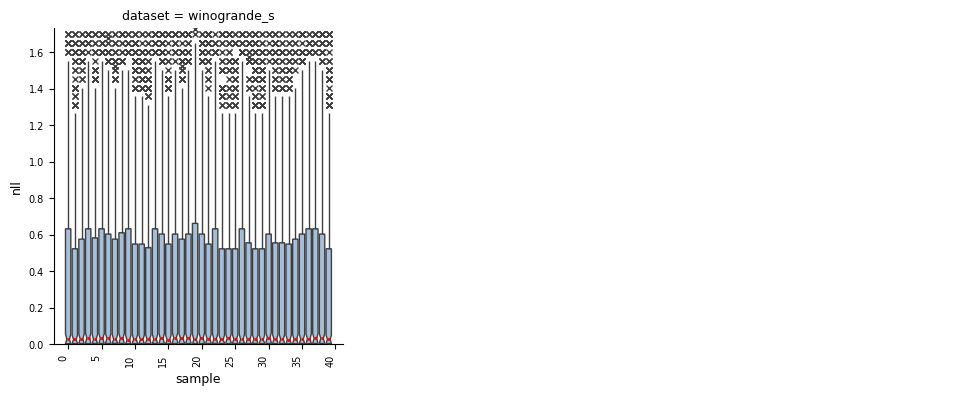

In [44]:
# boxplot with seaborn.catplot
# boxplot with seaborn.catplot
kwargs = dict( showcaps=False,
    notch=True,
    flierprops={"marker": "x"},
    boxprops={"facecolor": (.3, .5, .7, .5)},
    medianprops={"color": "r", "linewidth": 2},
)
g = sns.catplot(data=df_scala, col="dataset", x="sample", y="nll", kind="box", height=4, aspect=.8, col_wrap=3, sharey=False, native_scale=True, **kwargs)

dg = df_scala.groupby('dataset')
# Set y-axis limits to max whisker length for each subplot
# import matplotlib.ticker as ticker
# formatter = ticker.StrMethodFormatter('{x:.2f}')

for ax in g.axes.flat:
    print(ax.get_title())
    group = dg.get_group(ax.get_title().split(' = ')[1])
    iqr = group.groupby('sample')['nll'].quantile(0.75).max() - group.groupby('sample')['nll'].quantile(0.25).min()
    y_max = group.groupby('sample')['nll'].quantile(0.75).max() + 1.5 * iqr
    ax.set_ylim(0, y_max * 1.05)  # Add 5% padding
    plt.setp(ax.get_xticklabels(), rotation=90, ha='right')
    # ax.xaxis.set_major_formatter(formatter)

In [94]:
df = pd.read_parquet("nll_across_datasets.parquet")
df['dataset'] = df['dataset'].map(lambda x: '_'.join(x.split('_')[:-1]))
df['Method'] = 'Ours'
df['sample'] = (df['t'] * (len(df['t'].unique())-1)).astype(int)
# df.rename(columns={'t': 'sample'}, inplace=True)
df_combined = pd.concat([df, df_scala], ignore_index=True)
df_combined['data_id'] = df_combined.groupby(['dataset', 'sample', 'Method']).cumcount()
df_combined

,t,nll,dataset,Method,sample,index,data_id
0,0.0,0.000069,ARC-Easy,Ours,0,NaN,0
1,0.0,0.000004,ARC-Easy,Ours,0,NaN,1
2,0.0,-0.000000,ARC-Easy,Ours,0,NaN,2
3,0.0,-0.000000,ARC-Easy,Ours,0,NaN,3
4,0.0,-0.000000,ARC-Easy,Ours,0,NaN,4
...,...,...,...,...,...,...,...
186555,NaN,5.255234,winogrande_s,ScalaBL,39,1259.0,1259
186556,NaN,0.000856,winogrande_s,ScalaBL,39,1260.0,1260
186557,NaN,0.006716,winogrande_s,ScalaBL,39,1261.0,1261
186558,NaN,0.000912,winogrande_s,ScalaBL,39,1262.0,1262


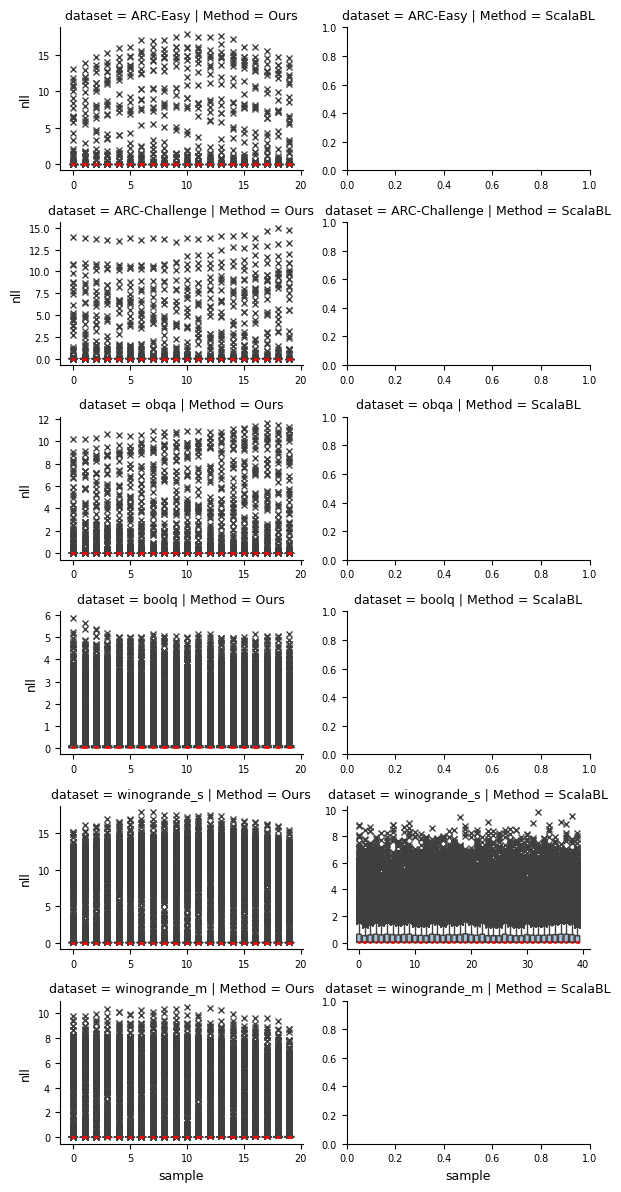

In [95]:

# boxplot with seaborn.catplot
sns.catplot(data=df_combined, row="dataset", col='Method', x="sample", y="nll", kind="box", height=2, aspect=1.5, sharex=False, sharey=False, native_scale=True, **kwargs)

dataset = ARC-Easy | Method = Ours
dataset = ARC-Easy | Method = ScalaBL
dataset = ARC-Challenge | Method = Ours
dataset = ARC-Challenge | Method = ScalaBL
dataset = obqa | Method = Ours
dataset = obqa | Method = ScalaBL
dataset = boolq | Method = Ours
dataset = boolq | Method = ScalaBL
dataset = winogrande_s | Method = Ours
dataset = winogrande_s | Method = ScalaBL
dataset = winogrande_m | Method = Ours
dataset = winogrande_m | Method = ScalaBL


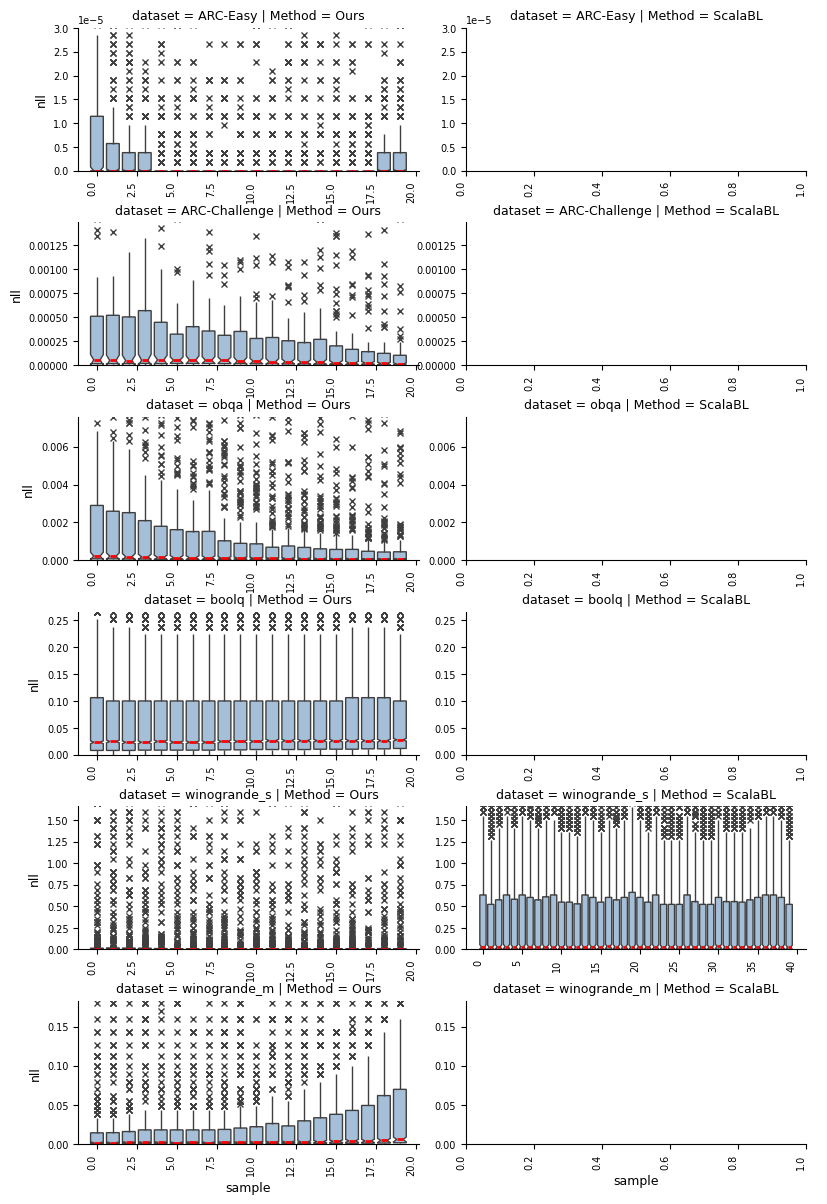

In [83]:

g = sns.catplot(data=df_combined, col='Method', row="dataset", x="sample", y="nll", kind="box", height=2, aspect=2, sharey=False, sharex=False, native_scale=True, **kwargs)

dg = df_combined.groupby('dataset')
# Set y-axis limits to max whisker length for each subplot
# import matplotlib.ticker as ticker
# formatter = ticker.StrMethodFormatter('{x:.2f}')

for ax in g.axes.flat:
    print(ax.get_title())
    group = dg.get_group(ax.get_title().split(' = ')[1].split(' | ')[0])
    iqr = group.groupby('sample')['nll'].quantile(0.75).max() - group.groupby('sample')['nll'].quantile(0.25).min()
    y_max = group.groupby('sample')['nll'].quantile(0.75).max() + 1.5 * iqr
    ax.set_ylim(0, y_max * 1.05)  # Add 5% padding
    plt.setp(ax.get_xticklabels(), rotation=90, ha='right')
    # ax.xaxis.set_major_formatter(formatter)

In [81]:
# load our results
logits_load = dict(np.load('test_logits.npz', allow_pickle=True))
nlls = {}

for ds, data in logits_load.items():
    try:
        logit = data.item()['logit']
        labels = data.item()['labels']
    except:
        logit = data['logit']
        labels = data['labels']
    
    nll = -Categorical(logits=logit).log_prob(labels[None, :])
    print(f"NLL mean: {nll.mean():.2f} \t Dataset: {ds}, NLL shape: {nll.shape},")
    nlls[ds] = nll

NLL mean: 0.34 	 Dataset: ARC-Easy_dataset:v0, NLL shape: (20, 500),
NLL mean: 0.69 	 Dataset: ARC-Challenge_dataset:v0, NLL shape: (20, 200),
NLL mean: 0.42 	 Dataset: obqa_dataset:v0, NLL shape: (20, 500),
NLL mean: 0.28 	 Dataset: boolq_dataset:v0, NLL shape: (20, 3200),
NLL mean: 2.00 	 Dataset: winogrande_s_dataset:v0, NLL shape: (20, 1200),
NLL mean: 0.89 	 Dataset: winogrande_m_dataset:v0, NLL shape: (20, 1200),


<Axes: xlabel='ScalaBL NLL', ylabel='Ours NLL'>

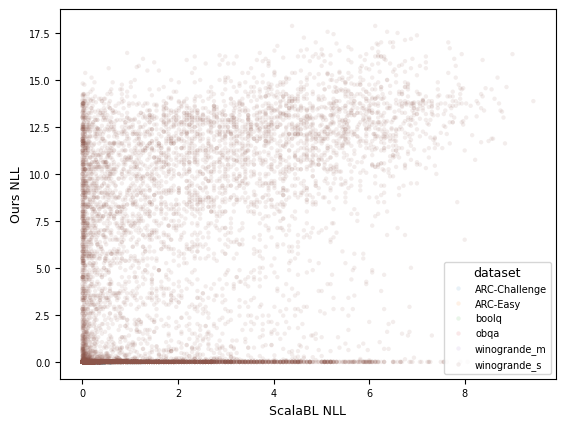

In [154]:
df_combined_piv = df_combined.pivot(index=['dataset', 'sample', 'data_id'], columns='Method', values='nll').reset_index()
df_combined_piv.rename(columns={'Ours': 'Ours NLL', 'ScalaBL': 'ScalaBL NLL'}, inplace=True)
sns.scatterplot(data=df_combined_piv, x='ScalaBL NLL', y='Ours NLL', hue='dataset', alpha=.1, s=10, linewidth=0)

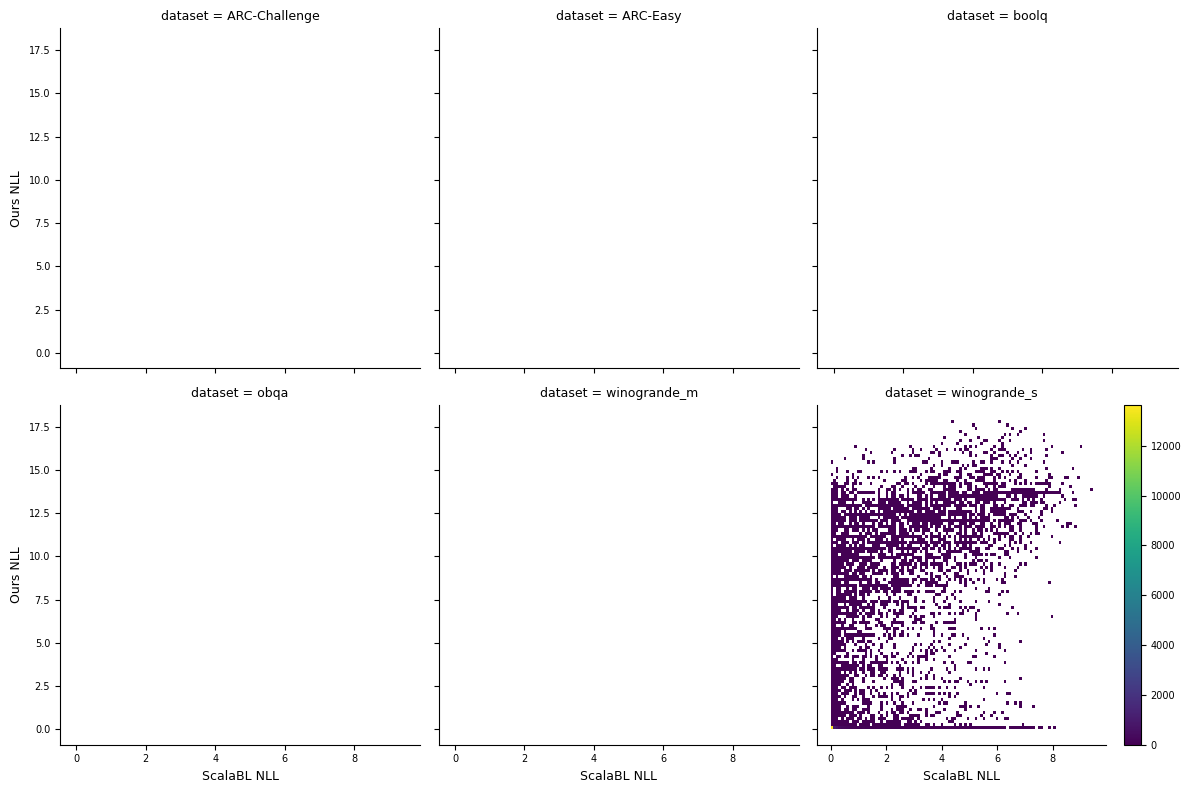

In [155]:
from matplotlib.colors import LogNorm, Normalize

g = sns.displot(data=df_combined_piv, x='ScalaBL NLL', y='Ours NLL', col='dataset', col_wrap=3, height=4, aspect=1, bins=100, cmap='viridis', kind='hist', hue_norm=LogNorm(13,20), cbar=True,)
# create a single colorbar for all facets using the QuadMesh from the first axis

Text(0.5, 1.0, 'winogrande_s')

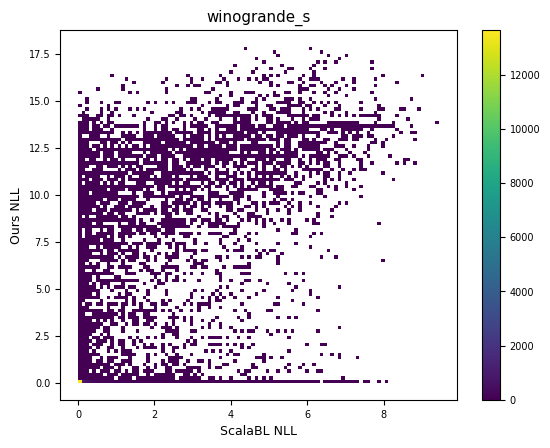

In [158]:
ax = sns.histplot(data=df_combined_piv[df_combined_piv['dataset'] == 'winogrande_s'], x='ScalaBL NLL', y='Ours NLL', bins=100, cmap='viridis', cbar=True)
ax.set_title('winogrande_s')


Text(0.5, 1.0, 'winogrande_s')

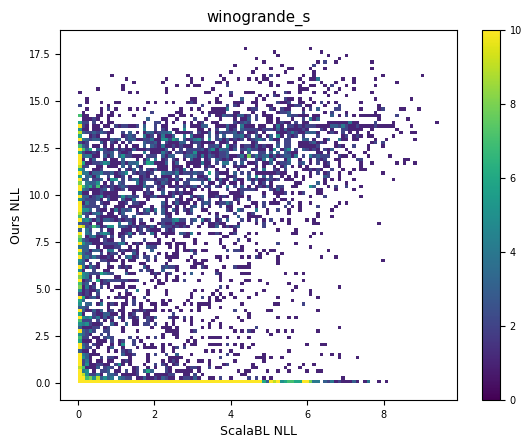

In [157]:
ax = sns.histplot(data=df_combined_piv[df_combined_piv['dataset'] == 'winogrande_s'], x='ScalaBL NLL', y='Ours NLL', bins=100, cmap='viridis', cbar=True, vmin=0, vmax=10)
ax.set_title('winogrande_s')


### compute functional diversity metrics 

In [148]:
# Sweep http://141.37.176.86:8080/ddold/qwen_PtoC/sweeps/m70skc3a/overview
# selected runs with seed == 1 and k in {2,5}
test_ids = ['oe79hwp5', 'r1mc5ewx', 'y7w5m8af', 'v74gcy9j', '2xgtqyg1', 'bpwgok1f',]
test_ids = ['r1mc5ewx', 'y7w5m8af'] # k=2
test_ids = ['75r2zxfp', '7c6avatp'] # k=5
test_ids = ['7c6avatp',] # k=5

# Sweep http://141.37.176.86:8080/ddold/qwen_PtoC/sweeps/00r8grro/overview
test_ids = ['uctcnfuc',] # k=2 As(t)B
# test_ids = ['j3xwle86',] # k=2 A(t)B(t)
test_ids = ['z0b9vrhr',] # k=2 A(t)B

# Sweep expert: http://141.37.176.86:8080/ddold/qwen_PtoC/sweeps/kw05n5kp/overview
# test_ids = ['etimnu2p',] # k=2 As(t)B sort=false
smoke = False

api = wandb.Api()

nlls = []
df = []
logits = {}
params_cache = {}
# for test_id in test_ids:
test_id = test_ids[0]
run = api.run(f"ddold/qwen_PtoC/{test_id}")

config = deepcopy(run.config)
# config['dataset_path'] = "artifacts/winogrande_s_dataset:v0/test_data.npz"
ds_name = config['dataset_path'].split("/")[-1]
print(f"Dataset name: {ds_name}")
config['dataset_path'] = f"artifacts/{ds_name}/test_data.npz"
config['net_kwargs'] = {
    'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
}

# run = wandb.init(project="qwen_PtoC", name="test_prediction")
test_input_ids, test_attention_mask, test_labels, test_target_ids, test_unique_target_ids = load_text_classification_data(config['dataset_path'], run=None)
key = jax.random.PRNGKey(config.get('rng_seed', 0))

print(test_input_ids.shape, test_attention_mask.shape, test_labels.shape, test_target_ids.shape, test_unique_target_ids.shape)
if smoke:
    test_input_ids = test_input_ids[:128]
    test_attention_mask = test_attention_mask[:128]
    test_labels = test_labels[:128]

s_model, params = init_model(config, test_unique_target_ids)
params, bma_stats = load_checkpoint(run, params, s_model)

t_space = jnp.array(bma_stats['t_space'])
rng_key, key = jax.random.split(key)
test_metrics_fn_final = setup_metrics(s_model, 32, test_input_ids, test_attention_mask, test_labels, n_samples=len(t_space), use_linspace=True, average=False, key_prefix='final_')
curve_metric, logits_test = test_metrics_fn_final(rng_key, params) # logits test with shape (n_samples, n_data, n_classes)
print(jax.tree.map(lambda x: x.mean(), curve_metric))
params_cache[ds_name] = jax.device_put(params, jax.devices("cpu")[0])

logits[ds_name] = dict(logit=logits_test, labels=test_labels, bma_weights=bma_stats['weights'], t_space=t_space)
jnp.savez(f"test_logits_{test_id}_fn.npz", **logits)

Dataset name: obqa_dataset:v0
(500, 127) (500, 127) (500,) (500,) (4, 1)
Found config with obqa dataset with name: dashing-sweep-37, id: z0b9vrhr
Loaded trainable_params from z0b9vrhr_trainable_params.npy
Loaded bma_weights from z0b9vrhr_weights.npz
{'final_acc': Array(0.90896004, dtype=float32), 'final_ece': Array(0.07293078, dtype=float32), 'final_loss': Array(0.44303358, dtype=float32)}


In [ ]:

# Sweep http://141.37.176.86:8080/ddold/qwen_PtoC/sweeps/00r8grro/overview
# test_id = 'uctcnfuc' # k=2 As(t)B
# test_id = 'j3xwle86' # k=2 A(t)B(t)
# test_id = 'z0b9vrhr' # k=2 A(t)B

# Sweep expert: http://141.37.176.86:8080/ddold/qwen_PtoC/sweeps/kw05n5kp/overview
test_id = 'etimnu2p' # k=2 As(t)B sort=false

# load our results
logits = dict(np.load(f'test_logits_{test_id}_fn.npz', allow_pickle=True))
# select dataset
ds = list(logits.keys())[0]
t_space = logits[ds].item()['t_space']
weights = logits[ds].item()['bma_weights']
logits_test = logits[ds].item()['logit']
labels = logits[ds].item()['labels']

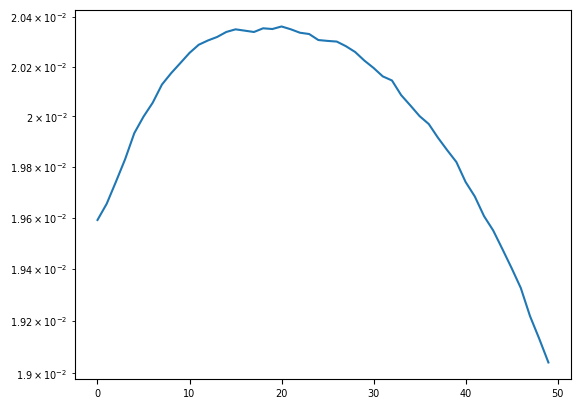

In [138]:
# p, bma_stats = load_checkpoint(run, params, s_model)
for b_w in weights:
    plt.plot(b_w.flatten())
plt.yscale('log')

In [139]:

def mutual_information(logits, weights:np.ndarray|bool=False):
    """Compute mutual information from logits over samples

    Args:
        logits: jnp.ndarray of shape (n_samples, n_data, n_classes)
    Returns:
        mi: float mutual information averaged over each data point
    """
    use_weigts = True if isinstance(weights, jnp.ndarray) or isinstance(weights, np.ndarray) else False
    probs = jax.nn.softmax(logits, axis=-1)  # (n_samples, n_data, n_classes)
    if use_weigts:
        avg_probs = jnp.sum(probs * weights[:, None, None], axis=0)  # (n_data, n_classes)
    else:
        avg_probs = jnp.mean(probs, axis=0)  # (n_data, n_classes)
    entropy_pred = -jnp.sum(avg_probs * jnp.log(avg_probs + 1e-12), axis=-1)  # (n_data,)
    if use_weigts:
        expected_nentropy = jnp.sum(-jnp.sum(probs * jnp.log(probs + 1e-12), axis=-1) * weights[:, None], axis=0)  # (n_data,)
    else:
        expected_nentropy = jnp.mean(-jnp.sum(probs * jnp.log(probs + 1e-12), axis=-1), axis=0)  # (n_data,)
    mi = entropy_pred - expected_nentropy  # (n_data,)
    return jnp.mean(mi)

def mean_entropy(logits, weights:np.ndarray|bool=False):
    """Compute curve entropy from logits over samples

    Args:
        logits: jnp.ndarray of shape (n_samples, n_data, n_classes)
    Returns:
        entropy: float predictive entropy averaged over each data point
    """
    use_weigts = True if isinstance(weights, jnp.ndarray) or isinstance(weights, np.ndarray) else False
    probs = jax.nn.softmax(logits, axis=-1)  # (n_samples, n_data, n_classes)
    if use_weigts:
        avg_probs = jnp.sum(probs * weights[:, None, None], axis=0)  # (n_data, n_classes)
    else:
        avg_probs = jnp.mean(probs, axis=0)  # (n_data, n_classes)
    entropy_pred = -jnp.sum(avg_probs * jnp.log(avg_probs + 1e-12), axis=-1)  # (n_data,)
    return jnp.mean(entropy_pred)

def entropy(logits):
    probs = jax.nn.softmax(logits, axis=-1)  # (n_samples, n_data, n_classes)
    entropies = -jnp.sum(probs * jnp.log(probs + 1e-12), axis=-1)  # (n_samples, n_data)
    return entropies  # (n_samples, n_data)

def mean_std_entropy(logits):
    ent = entropy(logits)  # (n_samples, n_data)
    return ent.std(axis=0).mean()  # float

In [140]:
for ds, data in logits.items():
    logit = data.item()['logit']
    labels = data.item()['labels']
    nll = -Categorical(logits=logit).log_prob(labels[None, :])
    mi = mutual_information(logit, weights=weights[0])
    # mi = mutual_information(logit)
    m_ent = mean_entropy(logit, weights=weights[0])
    ent = entropy(logit)
    std_ent = mean_std_entropy(logit)

    print("\tDataset :", ds)
    print("-"*50)
    print(f"NLL mean: {nll.mean():.2f} | MI {mi:.4f} | BMA Entropy {m_ent:.4f} | Std Entropy {std_ent:.4f}", "Mean Entropy:", ent.mean())
    print("-"*50)

	Dataset : obqa_dataset:v0
--------------------------------------------------
NLL mean: 0.34 | MI 0.0143 | BMA Entropy 0.1085 | Std Entropy 0.0353 Mean Entropy: 0.09418828
--------------------------------------------------


#### With scalaBL

In [141]:
 
file = np.load("../BayesAdapt/scalaBl_obqa_0.npz")
logits_scala, labels_scala = file['logits'], file['labels']
logits_scala = logits_scala.reshape(-1, *logits_scala.shape[2:]).transpose(1,0,2)
# print(logits_scala.shape)
labels_scala = labels_scala.reshape(-1).astype(int)
nll_scala = -Categorical(logits=logits_scala).log_prob(labels_scala[None, :])

probs_scala = jax.nn.softmax(logits_scala, axis=-1).mean(axis=0)
nll_scala_bma = -Categorical(probs=probs_scala).log_prob(labels_scala)

mi_s = mutual_information(logits_scala)
# mi = mutual_information(logit)
m_ent_s = mean_entropy(logits_scala)
ent_s = entropy(logits_scala)
std_ent_s = mean_std_entropy(logits_scala)

print("ScalaBL Results:")
print("\tDataset :", ds)
print("-"*50)
print(f"NLL mean: {nll_scala_bma.mean():.2f} | MI {mi_s:.4f} | BMA Entropy {m_ent_s:.4f} | Std Entropy {std_ent_s:.4f}", "Mean Entropy:", ent_s.mean())
print("-"*50)

ScalaBL Results:
	Dataset : obqa_dataset:v0
--------------------------------------------------
NLL mean: 0.23 | MI 0.0530 | BMA Entropy 0.2500 | Std Entropy 0.1178 Mean Entropy: 0.19704737
--------------------------------------------------


#### resume

Text(0, 0.5, 'Entropy across data points')

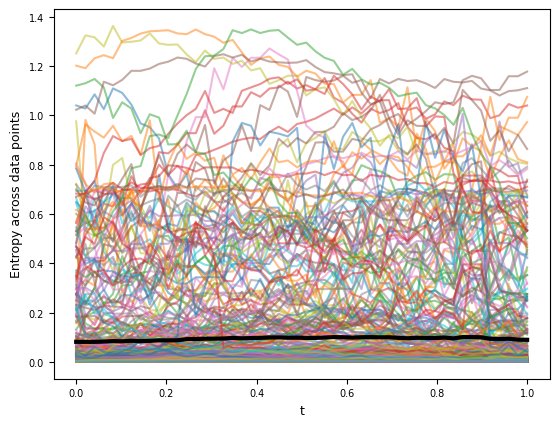

In [142]:
plt.plot(t_space, ent, alpha=0.5, linewidth=1.5, label='Entropy per data point')
plt.plot(t_space, ent.mean(-1), color='black', linewidth=3, label='Mean Entropy')
plt.xlabel('t')
plt.ylabel('Entropy across data points')

Text(0.5, 1.0, 'ScalaBL Sample Probabilities \nData: 191 (Max Entropy 1.2056)')

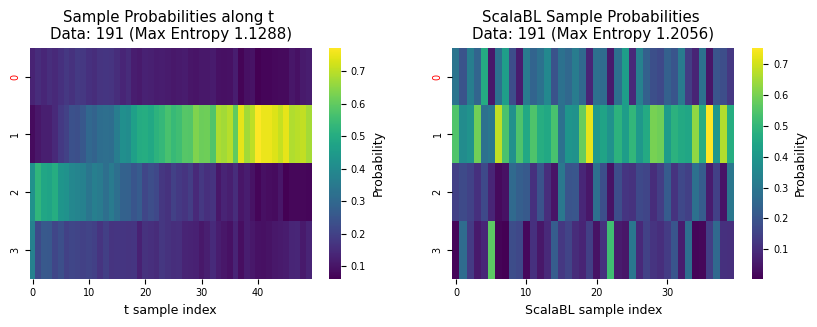

In [143]:
max_idx = ent.mean(0).argmax()
ds = ['ARC-Challenge_dataset:v0', 'obqa_dataset:v0'][1]
logit = logits[ds].item()['logit']
labels = logits[ds].item()['labels']

sample_logits = logit[:, max_idx, :]
sample_probs = jax.nn.softmax(sample_logits, axis=-1)

fig, ax = plt.subplots(1,2, figsize=(10, 3))

# plot our results
sns.heatmap(np.array(sample_probs.T), cmap='viridis', cbar_kws={'label': 'Probability'}, xticklabels=10, ax=ax[0])
ax[0].set_xlabel('t sample index')
xticks = np.arange(logit.shape[-1])
correct_class = int(labels[max_idx])
ax[0].set_yticks(xticks+0.5)
ax[0].set_yticklabels([str(i) for i in xticks])
for tl in ax[0].get_yticklabels():
    tl.set_color('red' if int(tl.get_text()) == correct_class else 'black')
ax[0].set_title(f'Sample Probabilities along t \nData: {max_idx} (Max Entropy {ent.mean(0).max():.4f})')

# plot scalaBL results
sample_logits_s = logits_scala[:, max_idx, :]
sample_probs_s = jax.nn.softmax(sample_logits_s, axis=-1)
sns.heatmap(np.array(sample_probs_s.T), cmap='viridis', cbar_kws={'label': 'Probability'}, xticklabels=10, ax=ax[1])
ax[1].set_xlabel('ScalaBL sample index')
xticks = np.arange(logits_scala.shape[-1])
correct_class = int(labels_scala[max_idx])
ax[1].set_yticks(xticks+0.5)
ax[1].set_yticklabels([str(i) for i in xticks])
for tl in ax[1].get_yticklabels():
    tl.set_color('red' if int(tl.get_text()) == correct_class else 'black')
ax[1].set_title(f'ScalaBL Sample Probabilities \nData: {max_idx} (Max Entropy {ent_s.mean(0).max():.4f})')

Text(0.5, 1.0, 'ScalaBL Sample Probabilities \nData: 211 (Max NLL 5.1595)')

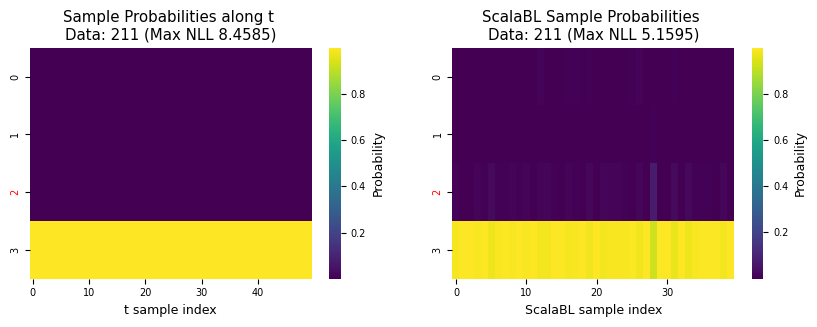

In [144]:
max_idx = nll.mean(0).argmax()
ds = ['ARC-Challenge_dataset:v0', 'obqa_dataset:v0'][1]
logit = logits[ds].item()['logit']
labels = logits[ds].item()['labels']

sample_logits = logit[:, max_idx, :]
sample_probs = jax.nn.softmax(sample_logits, axis=-1)

fig, ax = plt.subplots(1,2, figsize=(10, 3))

# plot our results
sns.heatmap(np.array(sample_probs.T), cmap='viridis', cbar_kws={'label': 'Probability'}, xticklabels=10, ax=ax[0])
ax[0].set_xlabel('t sample index')
xticks = np.arange(logit.shape[-1])
correct_class = int(labels[max_idx])
ax[0].set_yticks(xticks+0.5)
ax[0].set_yticklabels([str(i) for i in xticks])
for tl in ax[0].get_yticklabels():
    tl.set_color('red' if int(tl.get_text()) == correct_class else 'black')
ax[0].set_title(f'Sample Probabilities along t \nData: {max_idx} (Max NLL {nll.mean(0).max():.4f})')

# plot scalaBL results
sample_logits_s = logits_scala[:, max_idx, :]
sample_probs_s = jax.nn.softmax(sample_logits_s, axis=-1)
sns.heatmap(np.array(sample_probs_s.T), cmap='viridis', cbar_kws={'label': 'Probability'}, xticklabels=10, ax=ax[1])
ax[1].set_xlabel('ScalaBL sample index')
xticks = np.arange(logits_scala.shape[-1])
correct_class = int(labels_scala[max_idx])
ax[1].set_yticks(xticks+0.5)
ax[1].set_yticklabels([str(i) for i in xticks])
for tl in ax[1].get_yticklabels():
    tl.set_color('red' if int(tl.get_text()) == correct_class else 'black')
ax[1].set_title(f'ScalaBL Sample Probabilities \nData: {max_idx} (Max NLL {nll_scala.mean(0).max():.4f})')

Text(0.5, 161.7222222222224, 'ScalaBL sample index')

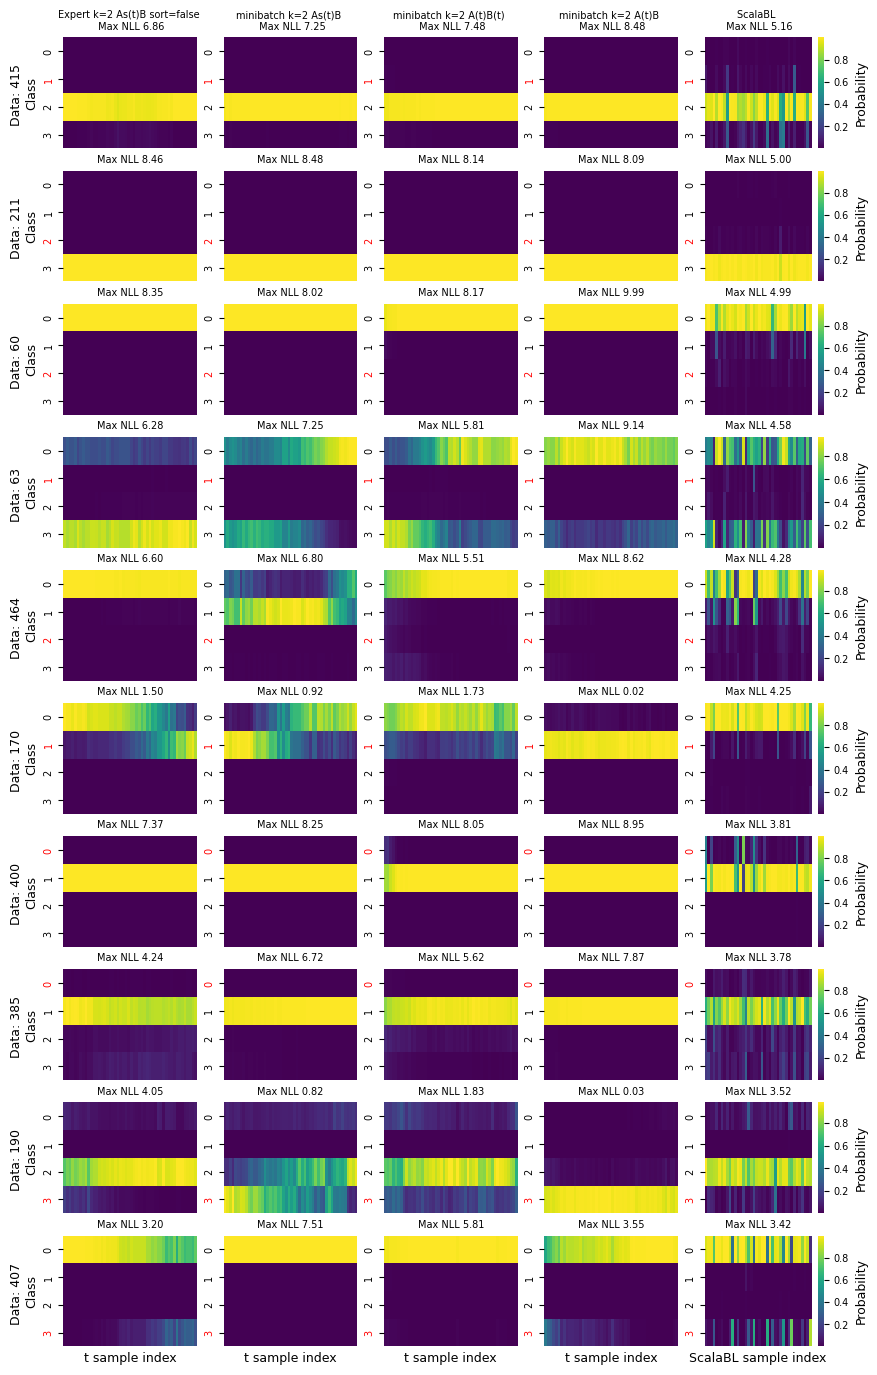

In [163]:
# plot top 10 uncertain data points
top_k = 10
ids = [['Expert k=2 As(t)B sort=false', 'etimnu2p'], ['minibatch k=2 As(t)B', 'uctcnfuc'], ['minibatch k=2 A(t)B(t)', 'j3xwle86'], ['minibatch k=2 A(t)B', 'z0b9vrhr'],]

logits = dict(np.load(f'test_logits_{ids[0][1]}_fn.npz', allow_pickle=True))
# select dataset
ds = list(logits.keys())[0]
logit = logits[ds].item()['logit']
labels = logits[ds].item()['labels']

nll = -Categorical(logits=logit).log_prob(labels[None, :])
# max_idx = nll.mean(0).argsort()[-top_k:][::-1]

# with scalaBL sorting
max_idx = nll_scala.mean(0).argsort()[-top_k:][::-1]

fig, ax = plt.subplots(top_k, len(ids)+1, figsize=(10, 1.7*top_k))

# plot our results
for i, idx in enumerate(max_idx):
    for j, (name, test_id) in enumerate(ids):
        logits = dict(np.load(f'test_logits_{test_id}_fn.npz', allow_pickle=True))
        # select dataset
        ds = list(logits.keys())[0]
        logit = logits[ds].item()['logit']
        labels = logits[ds].item()['labels']
        nll = -Categorical(logits=logit).log_prob(labels[None, :])
    
        sample_logits = logit[:, idx, :]
        sample_probs = jax.nn.softmax(sample_logits, axis=-1)
        sns.heatmap(np.array(sample_probs.T), cmap='viridis', xticklabels=10, ax=ax[i, j], cbar=False)
        xticks = np.arange(logit.shape[-1])
        correct_class = int(labels[idx])
        ax[i, j].set_yticks(xticks+0.5)
        ax[i, j].set_yticklabels([str(i) for i in xticks])
        for tl in ax[i, j].get_yticklabels():
            tl.set_color('red' if int(tl.get_text()) == correct_class else 'black')
        if i == 0:
            ax[i, j].set_title(f'{name} \n Max NLL {nll.mean(0)[idx]:.2f}', fontsize=7)
        else:
            ax[i, j].set_title(f'Max NLL {nll.mean(0)[idx]:.2f}', fontsize=7)
        ax[i, j].set_xticks([])
        if j == 0:
            ax[i, j].set_ylabel(f'Data: {idx} \nClass')

    # plot scalaBL results
    sample_logits_s = logits_scala[:, idx, :]
    sample_probs_s = jax.nn.softmax(sample_logits_s, axis=-1)
    sns.heatmap(np.array(sample_probs_s.T), cmap='viridis', cbar_kws={'label': 'Probability'}, xticklabels=10, ax=ax[i, -1])
    # ax[i, -1].set_xlabel('ScalaBL sample index')
    xticks = np.arange(logits_scala.shape[-1])
    correct_class = int(labels_scala[idx])
    ax[i, -1].set_yticks(xticks+0.5)
    ax[i, -1].set_yticklabels([str(i) for i in xticks])
    for tl in ax[i, -1].get_yticklabels():
        tl.set_color('red' if int(tl.get_text()) == correct_class else 'black')

    if i == 0:
        ax[i, -1].set_title(f'ScalaBL \n Max NLL {nll_scala.mean(0)[idx]:.2f}', fontsize=7)
    else:
        ax[i, -1].set_title(f'Max NLL {nll_scala.mean(0)[idx]:.2f}', fontsize=7)
    ax[i, -1].set_xticks([])
for axx in ax[-1, :-1]:
    axx.set_xlabel('t sample index')
ax[-1, -1].set_xlabel('ScalaBL sample index')

Text(0.5, 161.7222222222224, 'ScalaBL sample index')

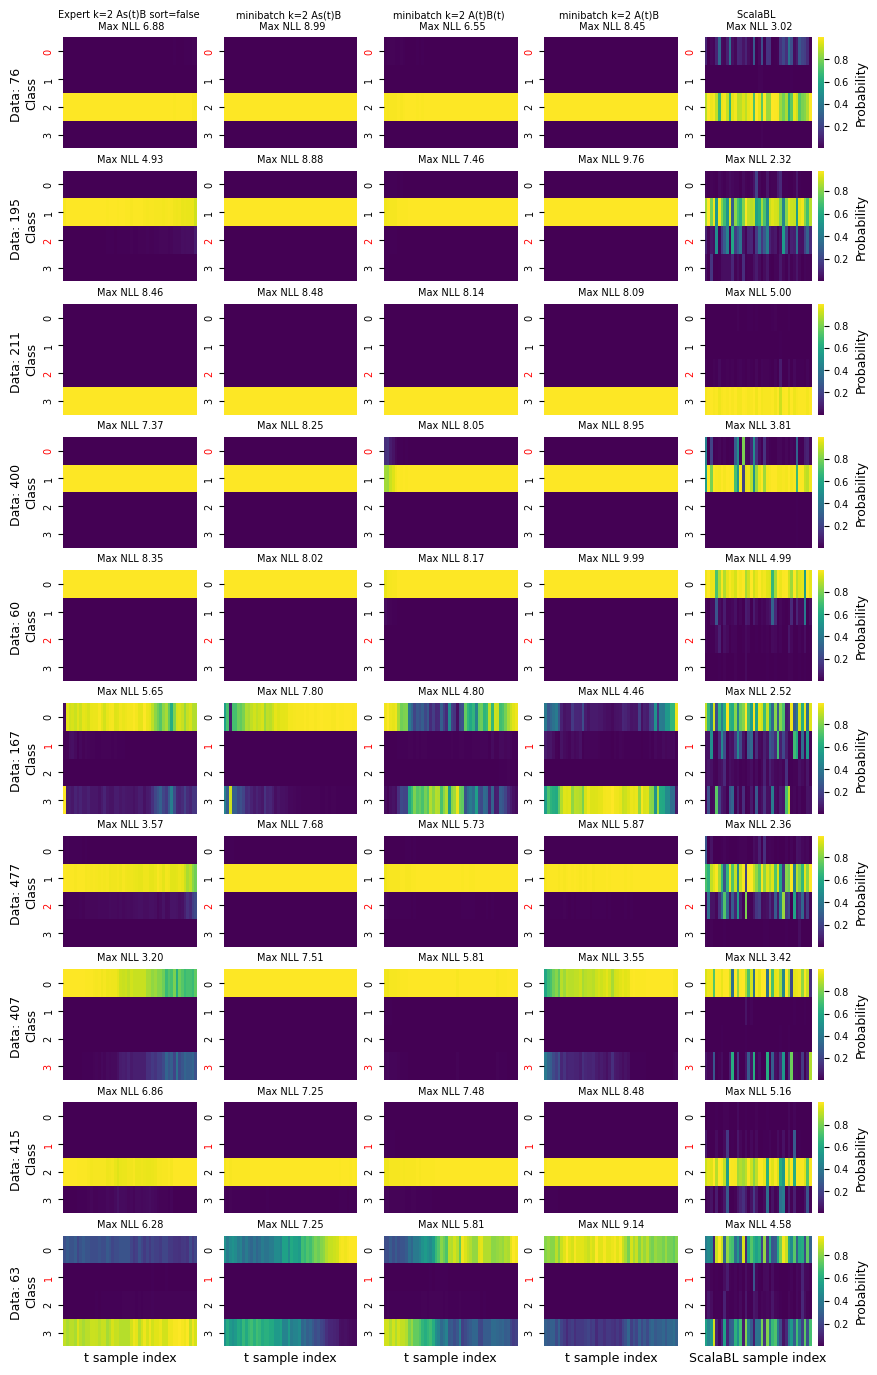

In [162]:
# plot top 10 uncertain data points
top_k = 10
ids = [['Expert k=2 As(t)B sort=false', 'etimnu2p'], ['minibatch k=2 As(t)B', 'uctcnfuc'], ['minibatch k=2 A(t)B(t)', 'j3xwle86'], ['minibatch k=2 A(t)B', 'z0b9vrhr'],]

logits = dict(np.load(f'test_logits_{ids[1][1]}_fn.npz', allow_pickle=True))
# select dataset
ds = list(logits.keys())[0]
logit = logits[ds].item()['logit']
labels = logits[ds].item()['labels']

nll = -Categorical(logits=logit).log_prob(labels[None, :])
max_idx = nll.mean(0).argsort()[-top_k:][::-1]

fig, ax = plt.subplots(top_k, len(ids)+1, figsize=(10, 1.7*top_k))

# plot our results
for i, idx in enumerate(max_idx):
    for j, (name, test_id) in enumerate(ids):
        logits = dict(np.load(f'test_logits_{test_id}_fn.npz', allow_pickle=True))
        # select dataset
        ds = list(logits.keys())[0]
        logit = logits[ds].item()['logit']
        labels = logits[ds].item()['labels']
        nll = -Categorical(logits=logit).log_prob(labels[None, :])
    
        sample_logits = logit[:, idx, :]
        sample_probs = jax.nn.softmax(sample_logits, axis=-1)
        sns.heatmap(np.array(sample_probs.T), cmap='viridis', xticklabels=10, ax=ax[i, j], cbar=False)
        xticks = np.arange(logit.shape[-1])
        correct_class = int(labels[idx])
        ax[i, j].set_yticks(xticks+0.5)
        ax[i, j].set_yticklabels([str(i) for i in xticks])
        for tl in ax[i, j].get_yticklabels():
            tl.set_color('red' if int(tl.get_text()) == correct_class else 'black')
        if i == 0:
            ax[i, j].set_title(f'{name} \n Max NLL {nll.mean(0)[idx]:.2f}', fontsize=7)
        else:
            ax[i, j].set_title(f'Max NLL {nll.mean(0)[idx]:.2f}', fontsize=7)
        ax[i, j].set_xticks([])
        if j == 0:
            ax[i, j].set_ylabel(f'Data: {idx} \nClass')

    # plot scalaBL results
    sample_logits_s = logits_scala[:, idx, :]
    sample_probs_s = jax.nn.softmax(sample_logits_s, axis=-1)
    sns.heatmap(np.array(sample_probs_s.T), cmap='viridis', cbar_kws={'label': 'Probability'}, xticklabels=10, ax=ax[i, -1])
    # ax[i, -1].set_xlabel('ScalaBL sample index')
    xticks = np.arange(logits_scala.shape[-1])
    correct_class = int(labels_scala[idx])
    ax[i, -1].set_yticks(xticks+0.5)
    ax[i, -1].set_yticklabels([str(i) for i in xticks])
    for tl in ax[i, -1].get_yticklabels():
        tl.set_color('red' if int(tl.get_text()) == correct_class else 'black')

    if i == 0:
        ax[i, -1].set_title(f'ScalaBL \n Max NLL {nll_scala.mean(0)[idx]:.2f}', fontsize=7)
    else:
        ax[i, -1].set_title(f'Max NLL {nll_scala.mean(0)[idx]:.2f}', fontsize=7)
    ax[i, -1].set_xticks([])
for axx in ax[-1, :-1]:
    axx.set_xlabel('t sample index')
ax[-1, -1].set_xlabel('ScalaBL sample index')

Text(0.5, 161.7222222222224, 'ScalaBL sample index')

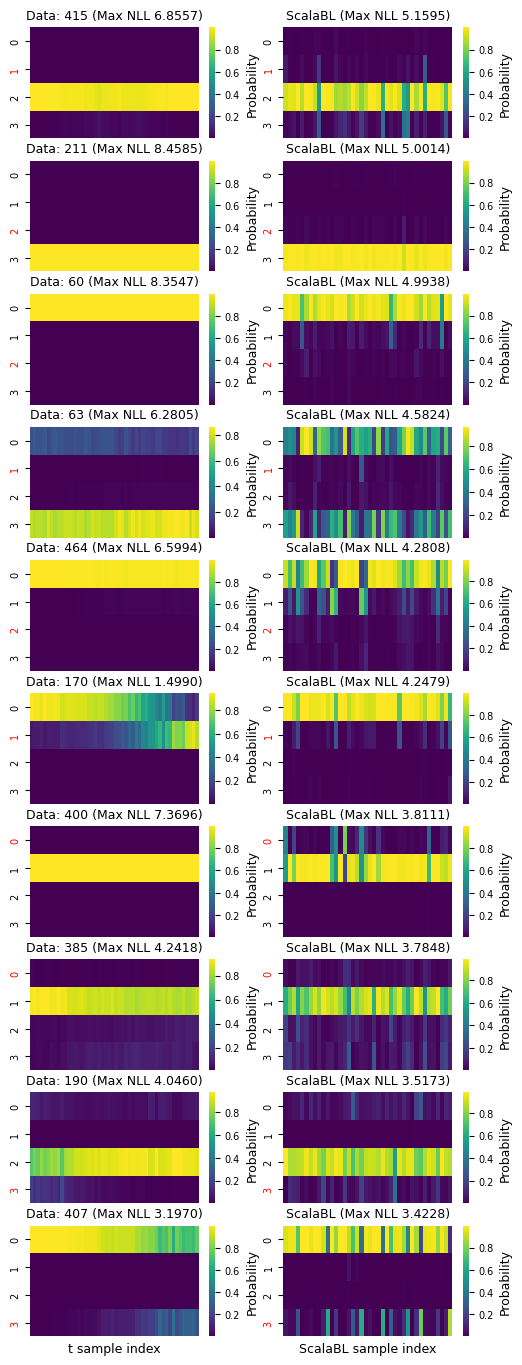

In [146]:
# plot top 20 uncertain data points
top_k = 10

max_idx = nll_scala.mean(0).argsort()[-top_k:][::-1]
ds = ['ARC-Challenge_dataset:v0', 'obqa_dataset:v0'][1]
logit = logits[ds].item()['logit']
labels = logits[ds].item()['labels']


fig, ax = plt.subplots(top_k, 2, figsize=(6, 1.7*top_k))

# plot our results
for i, idx in enumerate(max_idx):
    sample_logits = logit[:, idx, :]
    sample_probs = jax.nn.softmax(sample_logits, axis=-1)
    sns.heatmap(np.array(sample_probs.T), cmap='viridis', cbar_kws={'label': 'Probability'}, xticklabels=10, ax=ax[i, 0])
    xticks = np.arange(logit.shape[-1])
    correct_class = int(labels[idx])
    ax[i, 0].set_yticks(xticks+0.5)
    ax[i, 0].set_yticklabels([str(i) for i in xticks])
    for tl in ax[i, 0].get_yticklabels():
        tl.set_color('red' if int(tl.get_text()) == correct_class else 'black')
    ax[i, 0].set_title(f'Data: {idx} (Max NLL {nll.mean(0)[idx]:.4f})', fontsize=9)
    ax[i, 0].set_xticks([])

    # plot scalaBL results
    sample_logits_s = logits_scala[:, idx, :]
    sample_probs_s = jax.nn.softmax(sample_logits_s, axis=-1)
    sns.heatmap(np.array(sample_probs_s.T), cmap='viridis', cbar_kws={'label': 'Probability'}, xticklabels=10, ax=ax[i, 1])
    # ax[i, 1].set_xlabel('ScalaBL sample index')
    xticks = np.arange(logits_scala.shape[-1])
    correct_class = int(labels_scala[idx])
    ax[i, 1].set_yticks(xticks+0.5)
    ax[i, 1].set_yticklabels([str(i) for i in xticks])
    for tl in ax[i, 1].get_yticklabels():
        tl.set_color('red' if int(tl.get_text()) == correct_class else 'black')
    ax[i, 1].set_title(f'ScalaBL (Max NLL {nll_scala.mean(0)[idx]:.4f})', fontsize=9)
    ax[i, 1].set_xticks([])
ax[-1, 0].set_xlabel('t sample index')
ax[-1, 1].set_xlabel('ScalaBL sample index')

### analyse parameter differences along the curve

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from src.subspace_curve import masked_pytree_to_matrix, OrthoSpan, bezier_curve

def load_run(run_id):
    run = api.run(f"ddold/qwen_PtoC/{run_id}")

    config = deepcopy(run.config)
    # config['dataset_path'] = "artifacts/winogrande_s_dataset:v0/test_data.npz"
    ds_name = config['dataset_path'].split("/")[-1]
    print(f"Dataset name: {ds_name}")
    config['dataset_path'] = f"artifacts/{ds_name}/test_data.npz"
    config['net_kwargs'] = {
        'model_path': "artifacts/qwen2.5_7B_bfloat16:v0/",
    }
    # run = wandb.init(project="qwen_PtoC", name="test_prediction")
    test_input_ids, test_attention_mask, test_labels, test_target_ids, test_unique_target_ids = load_text_classification_data(config['dataset_path'], run=None)
    key = jax.random.PRNGKey(config.get('rng_seed', 0))
    print(test_input_ids.shape, test_attention_mask.shape, test_labels.shape, test_target_ids.shape, test_unique_target_ids.shape)

    s_model, params = init_model(config, test_unique_target_ids)
    params, bma_stats = load_checkpoint(run, params, s_model)
    return s_model, params, bma_stats, test_input_ids, test_attention_mask, test_labels


# define t_lambda to phi mapping using bezier curve (get point in varphi space from lambda (t))
def init_t_lambda_to_phi(cp_phi, k,):
    curve, d_bezier = bezier_curve(k+1, cp_phi)
    def clousure(t):
        space_point = curve(t)
        return space_point
    return jax.jit(clousure), curve, d_bezier


#### with curve k=2
http://141.37.176.86:8080/ddold/qwen_PtoC/sweeps/00r8grro/overview

In [5]:
del s_model, params, test_input_ids, test_attention_mask, test_labels, bma_stats

NameError: name 's_model' is not defined

In [10]:
# run_id = "l1zvbmw6" # minibatch K=5 As(t)B
# run_id = "ykegvoo6" # minibatch K=5 A(t)B(t)
# run_id = 'r0vdpdt2' # expert K=2 As(t)B
run_id = "uctcnfuc" # minibatch K=2 As(t)B
s_model, params, bma_stats, test_input_ids, test_attention_mask, test_labels = load_run(run_id)


Dataset name: obqa_dataset:v0
(500, 127) (500, 127) (500,) (500,) (4, 1)
Found config with obqa dataset with name: usual-sweep-45, id: uctcnfuc
Loaded trainable_params from uctcnfuc_trainable_params.npy
Loaded bma_weights from uctcnfuc_weights.npz


In [7]:
from src.subspace_curve import masked_pytree_to_matrix, OrthoSpan, bezier_curve


cp_w = masked_pytree_to_matrix(params['params'], s_model.curve_mask, s_model.k)
print(f"Control points shape: {cp_w.shape}")
cp_wNorm = cp_w / jnp.linalg.norm(cp_w, axis=1, keepdims=True)
cosine_sim = jnp.dot(cp_wNorm, cp_wNorm.T)
print(f"Cosine similarity between control points:\n {cosine_sim}")

# define the transformation function between weight space and phi space
t_phi_to_weight = OrthoSpan(cp_w)

# control points in the varphi space
cp_phi = t_phi_to_weight.inv(cp_w)
print(f"Control points in phi space: {cp_phi.shape}")
cp_phiNorm = cp_phi / jnp.linalg.norm(cp_phi, axis=1, keepdims=True)
cosine_sim = jnp.dot(cp_phiNorm, cp_phiNorm.T)
print(f"Cosine similarity between control points in phi space:\n {cosine_sim}")

t_lambda_to_phi, curve, _ = init_t_lambda_to_phi(cp_phi, s_model.k)



Control points shape: (3, 3648)
Cosine similarity between control points:
 [[0.99932384 0.03366963 0.05806214]
 [0.03366963 0.9992898  0.03050736]
 [0.05806214 0.03050736 0.99930406]]
Control points in phi space: (3, 2)
Cosine similarity between control points in phi space:
 [[ 1.         -0.50010586 -0.49985635]
 [-0.50010586  1.0000001  -0.5000379 ]
 [-0.49985635 -0.5000379   1.0000002 ]]


(100, 2)


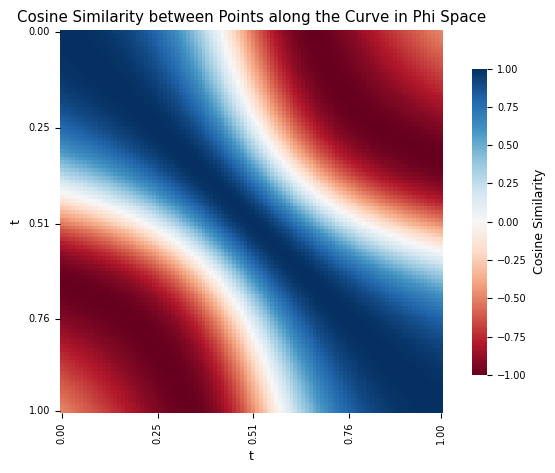

In [8]:
import numpy as np

# k = 2
t_space = jnp.linspace(0., 1., 100)
vec = jax.vmap(t_lambda_to_phi, (0,))(t_space)
print(vec.shape)

vec = vec / jnp.linalg.norm(vec, axis=1, keepdims=True)
cosine_sim = jnp.dot(vec, vec.T)

indices = [0, 25, 50, 75, 99]
t_vals = np.asarray(t_space)
labels = [f"{v:.2f}" for v in t_vals[indices]]

ax = sns.heatmap(cosine_sim, cmap='RdBu', vmin=-1., vmax=1., square=True, cbar_kws={"shrink": 0.8, "label": "Cosine Similarity"})
plt.title('Cosine Similarity between Points along the Curve in Phi Space')
ax.set_xticks(np.array(indices)+0.5)
ax.set_xticklabels(labels)
ax.set_yticks(np.array(indices)+0.5)
ax.set_yticklabels(labels)
ax.set_xlabel('t')
ax.set_ylabel('t')
plt.tight_layout()

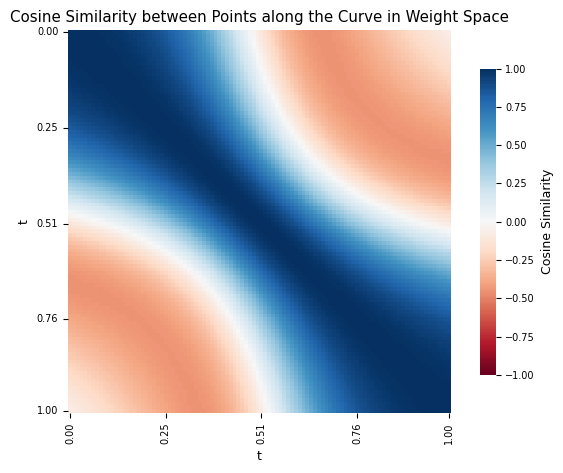

In [9]:
# k = 5 in weight space
vec_w = t_phi_to_weight(vec)
vec_w = vec_w / jnp.linalg.norm(vec_w, axis=1, keepdims=True)
cosine_sim_w = jnp.dot(vec_w, vec_w.T)

ax = sns.heatmap(cosine_sim_w, cmap='RdBu', vmin=-1., vmax=1., square=True, cbar_kws={"shrink": 0.8, "label": "Cosine Similarity"})
plt.title('Cosine Similarity between Points along the Curve in Weight Space')
ax.set_xticks(np.array(indices)+0.5)
ax.set_xticklabels(labels)
ax.set_yticks(np.array(indices)+0.5)
ax.set_yticklabels(labels)
ax.set_xlabel('t')
ax.set_ylabel('t')
plt.tight_layout()

$∣∣a−b∣∣^2=∣∣a∣∣^2+∣∣b∣∣^2−2⟨a,b⟩$

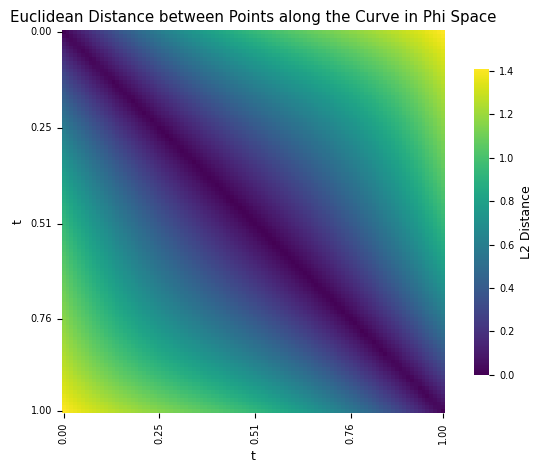

In [10]:
vec = jax.vmap(t_lambda_to_phi, (0,))(t_space)

# compute pairwise Euclidean distance between rows of vec and store in `cosine_sim`
# ∣∣a−b∣∣2=∣∣a∣∣2+∣∣b∣∣2−2⟨a,b⟩
sq_norms = jnp.sum(vec ** 2, axis=1)
d2 = sq_norms[:, None] + sq_norms[None, :] - 2 * (vec @ vec.T)
euclidean_dist = jnp.sqrt(jnp.maximum(d2, 0.0))

ax = sns.heatmap(euclidean_dist, cmap='viridis', square=True, cbar_kws={"shrink": 0.8, "label": "L2 Distance"})
plt.title('Euclidean Distance between Points along the Curve in Phi Space')
ax.set_xticks(np.array(indices)+0.5)
ax.set_xticklabels(labels)
ax.set_yticks(np.array(indices)+0.5)
ax.set_yticklabels(labels)
ax.set_xlabel('t')
ax.set_ylabel('t')
plt.tight_layout()

(100, 3648)


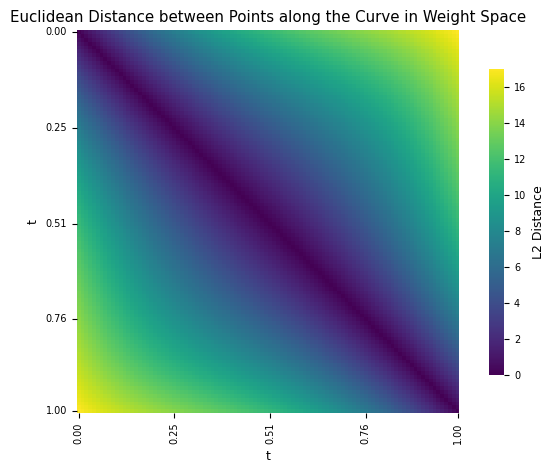

In [11]:
# = 5
vec = jax.vmap(t_lambda_to_phi, (0,))(t_space)
vec_w = t_phi_to_weight(vec)
print(vec_w.shape)

# compute pairwise Euclidean distance between rows of vec and store in `cosine_sim`
# ∣∣a−b∣∣2=∣∣a∣∣2+∣∣b∣∣2−2⟨a,b⟩
sq_norms = jnp.sum(vec_w ** 2, axis=1)
d2 = sq_norms[:, None] + sq_norms[None, :] - 2 * (vec_w @ vec_w.T)
euclidean_dist = jnp.sqrt(jnp.maximum(d2, 0.0))

ax = sns.heatmap(euclidean_dist, cmap='viridis', square=True, cbar_kws={"shrink": 0.8, "label": "L2 Distance"})
plt.title('Euclidean Distance between Points along the Curve in Weight Space')
ax.set_xticks(np.array(indices)+0.5)
ax.set_xticklabels(labels)
ax.set_yticks(np.array(indices)+0.5)
ax.set_yticklabels(labels)
ax.set_xlabel('t')
ax.set_ylabel('t')
plt.tight_layout()


##### per layer

In [62]:
from tqdm import tqdm

def cosine_sim_(t1, t2, params, mask):
    def cosine_sim_(t1, t2, p, k):
        p = p.reshape(k+1, -1)
        b_t, _ = bezier_curve(k+1, p)
        p_w = b_t(t1)
        # jax.debug.print(f"p_w shape: {t2.shape}")
        p_w2 = b_t(t2)
        p_w = p_w / jnp.linalg.norm(p_w)
        p_w2 = p_w2 / jnp.linalg.norm(p_w2)
        cos_sim = jnp.dot(p_w, p_w2)
        return jnp.array(cos_sim)
    return jax.tree.map(lambda p, m: cosine_sim_(t1, t2, p, s_model.k) if m else None, params, mask)


layer_cosine_sim = jax.vmap(jax.vmap(lambda t1, t2, p, m: cosine_sim_(t1, t2, p, m), in_axes=(None,0, None, None)), in_axes=(0,None,None,None))(t_space, t_space, params['params'], s_model.curve_mask)
layer_cosine_sim

{'embed_tokens': {'embedding': None},
 'layers_0': {'input_layernorm': {'weight': None},
  'mlp': {'down_proj': {'kernel': None},
   'gate_proj': {'kernel': None},
   'up_proj': {'kernel': None}},
  'post_attention_layernorm': {'weight': None},
  'self_attn': {'k_proj': {'bias': None, 'kernel': None},
   'o_proj': {'kernel': None},
   'q_proj': {'bias': None,
    'kernel': LoRA(A=None, s=[[0.99932337 0.99915    0.99845123 ... 0.04075243 0.03872274 0.03689517]
     [0.99915    0.99935687 0.9990437  ... 0.03981989 0.03740272 0.03519822]
     [0.99845123 0.9990437  0.99912184 ... 0.03906175 0.03625248 0.03366648]
     ...
     [0.04075243 0.03981989 0.03906175 ... 0.99933714 0.99904764 0.9985579 ]
     [0.03872274 0.03740272 0.03625248 ... 0.99904764 0.99915963 0.99906   ]
     [0.03689517 0.03519822 0.03366648 ... 0.9985579  0.99906    0.9993401 ]], B=None, w0=None) with dims=(1, 0) and lora_alpha=16)},
   'v_proj': {'bias': None,
    'kernel': LoRA(A=None, s=[[0.999267   0.99904066 0.99

In [63]:
# %%capture
n_imgs = len(jax.tree.leaves(layer_cosine_sim))
# fig, axes = plt.subplots(int(np.ceil(n_imgs/4)), 4, figsize=(16, 4*int(np.ceil(n_imgs/4))))
# axes = axes.flatten()
# pbar = tqdm(zip(axes, jax.tree.leaves_with_path(layer_cosine_sim)), total=n_imgs)
pbar = tqdm(jax.tree.leaves_with_path(layer_cosine_sim), total=n_imgs)
out_dir = "heatmap_frames"
os.makedirs(out_dir, exist_ok=True)
for name, cosine_sim in pbar:
    nn = "/".join([str(n.key) for n in name])
    pbar.set_description(f"Plotting layer: {nn}")
    # new figure per heatmap
    fig, ax = plt.subplots(figsize=(4, 4))
    ax = sns.heatmap(cosine_sim, cmap='RdBu', vmin=-1., vmax=1., square=True, cbar_kws={"shrink": 0.8, "label": "Cosine Similarity"}, ax=ax)
    ax.set_title(f'Layer: {nn}', fontsize=8)
    ax.set_xticks(np.array(indices)+0.5)
    ax.set_xticklabels(labels)
    ax.set_yticks(np.array(indices)+0.5)
    ax.set_yticklabels(labels)
    ax.set_xlabel('t')
    ax.set_ylabel('t')
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, f"{nn.replace('/', '_')}_cosine_sim.png"), dpi=150)
    plt.close(fig)

Plotting layer: layers_0/self_attn/q_proj/kernel/1:   0%|          | 0/57 [00:00<?, ?it/s]

Plotting layer: lm_head/kernel/1: 100%|██████████| 57/57 [00:12<00:00,  4.70it/s]                   


In [101]:
# --- GIF creation ---
from PIL import Image
import glob

png_paths = sorted(glob.glob(os.path.join(out_dir, "*_cosine_sim.png")))
# sort according to layer index
idx = [int(n.split('/')[1].split('_')[1]) if n.split('/')[1].split('_')[1] != 'head' else 1000  for n in png_paths]
idx = np.argsort(idx)
png_paths = np.array(png_paths)[idx]
frames = [Image.open(p).convert("P") for p in png_paths]
frames[0].save(
    "cosine_similarity_layers.gif",
    save_all=True,
    append_images=frames[1:],
    duration=300,
    loop=0,
    optimize=True
)


In [64]:
# --- GIF creation ---
from PIL import Image
import glob

png_paths = sorted(glob.glob(os.path.join(out_dir, "*_cosine_sim.png")))
# sort according to layer index
idx = [int(n.split('/')[1].split('_')[1]) if n.split('/')[1].split('_')[1] != 'head' else 1000  for n in png_paths]
idx = np.argsort(idx)
png_paths = np.array(png_paths)[idx]
frames = [Image.open(p).convert("P") for p in png_paths]

frames[0].save(
    "cosine_layers.webp",
    save_all=True,
    append_images=frames[1:],
    duration=300,
    loop=0
)

##### per layer but different weights


In [54]:
from tqdm import tqdm

def cosine_sim(t1, t2, param_1, params, mask):
    param_1 = param_1.reshape(s_model.k+1, -1)
    b_t_ref, _ = bezier_curve(s_model.k+1, param_1)
    def cosine_sim_(t1, t2, p, k):
        p = p.reshape(k+1, -1)
        b_t, _ = bezier_curve(k+1, p)
        p_w = b_t_ref(t1)
        # jax.debug.print(f"p_w shape: {t2.shape}")
        p_w2 = b_t(t2)
        p_w = p_w / jnp.linalg.norm(p_w)
        p_w2 = p_w2 / jnp.linalg.norm(p_w2)
        cos_sim = jnp.dot(p_w, p_w2)
        return jnp.array(cos_sim)
    return jax.tree.map(lambda p, m: cosine_sim_(t1, t2, p, s_model.k) if m else None, params, mask)

selected_param = params['params']['layers_0']['self_attn']['q_proj']['kernel'].s
t_space = jnp.linspace(0., 1., 100)
layer_cosine_sim = jax.vmap(jax.vmap(lambda t1, t2, pr, p, m: cosine_sim(t1, t2, pr, p, m), in_axes=(None,0, None, None, None)), in_axes=(0,None,None, None,None))(t_space, t_space, selected_param, params['params'], s_model.curve_mask)
layer_cosine_sim

{'embed_tokens': {'embedding': None},
 'layers_0': {'input_layernorm': {'weight': None},
  'mlp': {'down_proj': {'kernel': None},
   'gate_proj': {'kernel': None},
   'up_proj': {'kernel': None}},
  'post_attention_layernorm': {'weight': None},
  'self_attn': {'k_proj': {'bias': None, 'kernel': None},
   'o_proj': {'kernel': None},
   'q_proj': {'bias': None,
    'kernel': LoRA(A=None, s=[[0.99932337 0.99915    0.99845123 ... 0.04075243 0.03872274 0.03689517]
     [0.99915    0.99935687 0.9990437  ... 0.03981989 0.03740272 0.03519822]
     [0.99845123 0.9990437  0.99912184 ... 0.03906175 0.03625248 0.03366648]
     ...
     [0.04075243 0.03981989 0.03906175 ... 0.99933714 0.99904764 0.9985579 ]
     [0.03872274 0.03740272 0.03625248 ... 0.99904764 0.99915963 0.99906   ]
     [0.03689517 0.03519822 0.03366648 ... 0.9985579  0.99906    0.9993401 ]], B=None, w0=None) with dims=(1, 0) and lora_alpha=16)},
   'v_proj': {'bias': None,
    'kernel': LoRA(A=None, s=[[-0.02472395 -0.02391167 -0

In [55]:
# %%capture
n_imgs = len(jax.tree.leaves(layer_cosine_sim))
# fig, axes = plt.subplots(int(np.ceil(n_imgs/4)), 4, figsize=(16, 4*int(np.ceil(n_imgs/4))))
# axes = axes.flatten()
# pbar = tqdm(zip(axes, jax.tree.leaves_with_path(layer_cosine_sim)), total=n_imgs)
pbar = tqdm(jax.tree.leaves_with_path(layer_cosine_sim), total=n_imgs)
out_dir = "heatmap_frames_selected_param"
os.makedirs(out_dir, exist_ok=True)
indices =(np.linspace(0., 1., 5)*len(t_space)).round().astype(int)[:-1]
t_vals = np.asarray(t_space)
labels = [f"{v:.2f}" for v in t_vals[indices]]
for name, cosine_sim in pbar:
    nn = "/".join([str(n.key) for n in name])
    pbar.set_description(f"Plotting layer: {nn}")
    # new figure per heatmap
    fig, ax = plt.subplots(figsize=(4, 4))
    ax = sns.heatmap(cosine_sim, cmap='RdBu', vmin=-1., vmax=1., square=True, cbar_kws={"shrink": 0.8, "label": "Cosine Similarity"}, ax=ax)
    ax.set_title(f'Layer: {nn}', fontsize=8)
    ax.set_xticks(indices+0.5)
    ax.set_xticklabels(labels)
    ax.set_yticks(indices+0.5)
    ax.set_yticklabels(labels)
    ax.set_xlabel('t')
    ax.set_ylabel('t')
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, f"{nn.replace('/', '_')}_cosine_sim.png"), dpi=150)
    plt.close(fig)

Plotting layer: layers_0/self_attn/q_proj/kernel/1:   0%|          | 0/57 [00:00<?, ?it/s]

Plotting layer: lm_head/kernel/1: 100%|██████████| 57/57 [00:12<00:00,  4.73it/s]                   


In [60]:
# --- GIF creation ---
from PIL import Image
import glob

png_paths = sorted(glob.glob(os.path.join(out_dir, "*_cosine_sim.png")))
# sort according to layer index
idx = [int(n.split('/')[1].split('_')[1]) if n.split('/')[1].split('_')[1] != 'head' else 1000  for n in png_paths]
idx = np.argsort(idx)
png_paths = np.array(png_paths)[idx]
frames = [Image.open(p).convert("P") for p in png_paths]

frames[0].save(
    "cosine_layers_vs_layer0-q_proj.webp",
    save_all=True,
    append_images=frames[1:],
    duration=600,
    loop=0
)

#### with curve k=5
http://141.37.176.86:8080/ddold/qwen_PtoC/sweeps/00r8grro/overview

In [65]:
del s_model, params, test_input_ids, test_attention_mask, test_labels, bma_stats

In [66]:
run_id = "l1zvbmw6" # minibatch K=5 As(t)B
# run_id = "ykegvoo6" # minibatch K=5 A(t)B(t)
# run_id = 'r0vdpdt2' # expert K=2 As(t)B
# run_id = "uctcnfuc" # minibatch K=2 As(t)B
s_model, params, bma_stats, test_input_ids, test_attention_mask, test_labels = load_run(run_id)


Dataset name: obqa_dataset:v0
(500, 127) (500, 127) (500,) (500,) (4, 1)
Found config with obqa dataset with name: lucky-sweep-117, id: l1zvbmw6
Loaded trainable_params from l1zvbmw6_trainable_params.npy
Loaded bma_weights from l1zvbmw6_weights.npz


In [67]:
from src.subspace_curve import masked_pytree_to_matrix, OrthoSpan, bezier_curve


cp_w = masked_pytree_to_matrix(params['params'], s_model.curve_mask, s_model.k)
print(f"Control points shape: {cp_w.shape}")
cp_wNorm = cp_w / jnp.linalg.norm(cp_w, axis=1, keepdims=True)
cosine_sim = jnp.dot(cp_wNorm, cp_wNorm.T)
print(f"Cosine similarity between control points:\n {cosine_sim}")

# define the transformation function between weight space and phi space
t_phi_to_weight = OrthoSpan(cp_w)

# control points in the varphi space
cp_phi = t_phi_to_weight.inv(cp_w)
print(f"Control points in phi space: {cp_phi.shape}")
cp_phiNorm = cp_phi / jnp.linalg.norm(cp_phi, axis=1, keepdims=True)
cosine_sim = jnp.dot(cp_phiNorm, cp_phiNorm.T)
print(f"Cosine similarity between control points in phi space:\n {cosine_sim}")

t_lambda_to_phi, curve, _ = init_t_lambda_to_phi(cp_phi, s_model.k)



Control points shape: (6, 3648)
Cosine similarity between control points:
 [[0.99927294 0.03318154 0.0665971  0.0480384  0.05034765 0.05972874]
 [0.03318154 0.9992725  0.03767266 0.05333802 0.05496951 0.03374797]
 [0.0665971  0.03767266 0.9992876  0.04911622 0.01501656 0.02962294]
 [0.0480384  0.05333802 0.04911622 0.99929714 0.03729804 0.06451932]
 [0.05034765 0.05496951 0.01501656 0.03729804 0.9992869  0.04261813]
 [0.05972874 0.03374797 0.02962294 0.06451932 0.04261813 0.9993007 ]]
Control points in phi space: (6, 5)
Cosine similarity between control points in phi space:
 [[ 1.0000001  -0.19995984 -0.20009865 -0.19989753 -0.20005867 -0.20005453]
 [-0.19995984  1.0000002  -0.20003444 -0.19995673 -0.20004788 -0.20000641]
 [-0.20009865 -0.20003444  0.9999999  -0.20000008 -0.19998801 -0.19989347]
 [-0.19989753 -0.19995673 -0.20000008  0.9999999  -0.1999527  -0.20012593]
 [-0.20005867 -0.20004788 -0.19998801 -0.1999527   0.9999998  -0.19992529]
 [-0.20005453 -0.20000641 -0.19989347 -0.20

(100, 5)


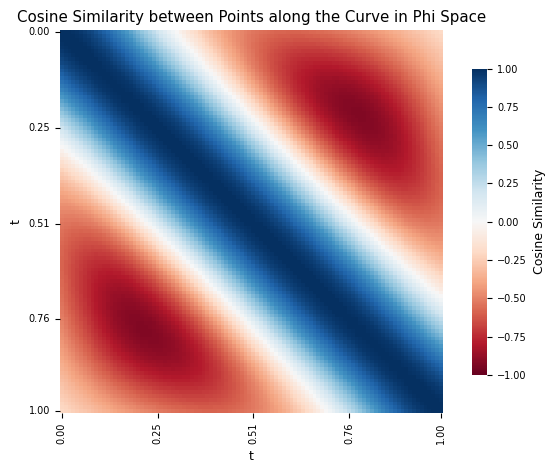

In [83]:
import numpy as np

# k = 5
t_space = jnp.linspace(0., 1., 100)
vec = jax.vmap(t_lambda_to_phi, (0,))(t_space)
print(vec.shape)

vec = vec / jnp.linalg.norm(vec, axis=1, keepdims=True)
cosine_sim = jnp.dot(vec, vec.T)

indices = [0, 25, 50, 75, 99]
t_vals = np.asarray(t_space)
labels = [f"{v:.2f}" for v in t_vals[indices]]

ax = sns.heatmap(cosine_sim, cmap='RdBu', vmin=-1., vmax=1., square=True, cbar_kws={"shrink": 0.8, "label": "Cosine Similarity"})
plt.title('Cosine Similarity between Points along the Curve in Phi Space')
ax.set_xticks(np.array(indices)+0.5)
ax.set_xticklabels(labels)
ax.set_yticks(np.array(indices)+0.5)
ax.set_yticklabels(labels)
ax.set_xlabel('t')
ax.set_ylabel('t')
plt.tight_layout()

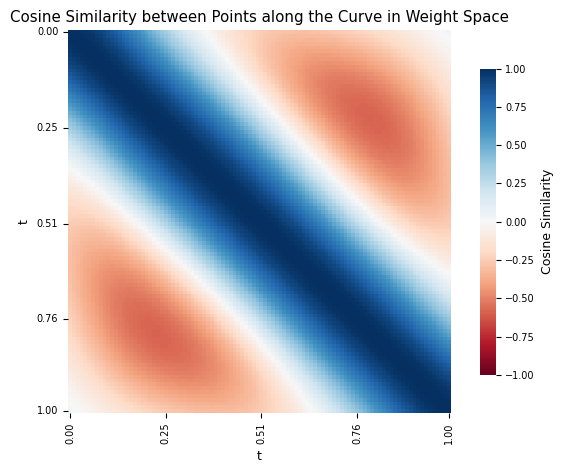

In [84]:
# k = 5 in weight space
vec_w = t_phi_to_weight(vec)
vec_w = vec_w / jnp.linalg.norm(vec_w, axis=1, keepdims=True)
cosine_sim_w = jnp.dot(vec_w, vec_w.T)

ax = sns.heatmap(cosine_sim_w, cmap='RdBu', vmin=-1., vmax=1., square=True, cbar_kws={"shrink": 0.8, "label": "Cosine Similarity"})
plt.title('Cosine Similarity between Points along the Curve in Weight Space')
ax.set_xticks(np.array(indices)+0.5)
ax.set_xticklabels(labels)
ax.set_yticks(np.array(indices)+0.5)
ax.set_yticklabels(labels)
ax.set_xlabel('t')
ax.set_ylabel('t')
plt.tight_layout()

$∣∣a−b∣∣^2=∣∣a∣∣^2+∣∣b∣∣^2−2⟨a,b⟩$

In [85]:
jnp.sqrt(0.)

Array(0., dtype=float32, weak_type=True)

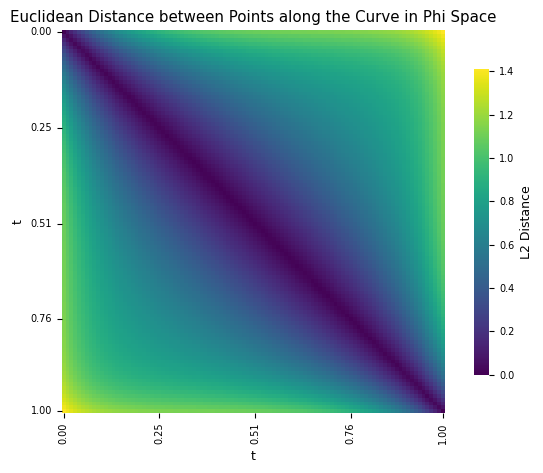

In [86]:
vec = jax.vmap(t_lambda_to_phi, (0,))(t_space)

# compute pairwise Euclidean distance between rows of vec and store in `cosine_sim`
# ∣∣a−b∣∣2=∣∣a∣∣2+∣∣b∣∣2−2⟨a,b⟩
sq_norms = jnp.sum(vec ** 2, axis=1)
d2 = sq_norms[:, None] + sq_norms[None, :] - 2 * (vec @ vec.T)
euclidean_dist = jnp.sqrt(jnp.maximum(d2, 0.0))

ax = sns.heatmap(euclidean_dist, cmap='viridis', square=True, cbar_kws={"shrink": 0.8, "label": "L2 Distance"})
plt.title('Euclidean Distance between Points along the Curve in Phi Space')
ax.set_xticks(np.array(indices)+0.5)
ax.set_xticklabels(labels)
ax.set_yticks(np.array(indices)+0.5)
ax.set_yticklabels(labels)
ax.set_xlabel('t')
ax.set_ylabel('t')
plt.tight_layout()

(100, 3648)


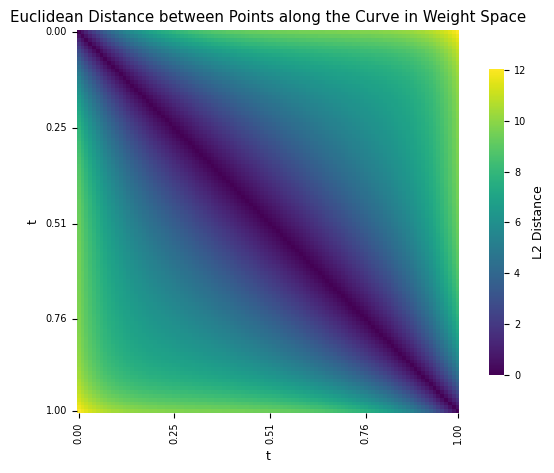

In [87]:
# = 5
vec = jax.vmap(t_lambda_to_phi, (0,))(t_space)
vec_w = t_phi_to_weight(vec)
print(vec_w.shape)

# compute pairwise Euclidean distance between rows of vec and store in `cosine_sim`
# ∣∣a−b∣∣2=∣∣a∣∣2+∣∣b∣∣2−2⟨a,b⟩
sq_norms = jnp.sum(vec_w ** 2, axis=1)
d2 = sq_norms[:, None] + sq_norms[None, :] - 2 * (vec_w @ vec_w.T)
euclidean_dist = jnp.sqrt(jnp.maximum(d2, 0.0))

ax = sns.heatmap(euclidean_dist, cmap='viridis', square=True, cbar_kws={"shrink": 0.8, "label": "L2 Distance"})
plt.title('Euclidean Distance between Points along the Curve in Weight Space')
ax.set_xticks(np.array(indices)+0.5)
ax.set_xticklabels(labels)
ax.set_yticks(np.array(indices)+0.5)
ax.set_yticklabels(labels)
ax.set_xlabel('t')
ax.set_ylabel('t')
plt.tight_layout()


In [ ]:
dd

##### per layer

In [68]:
from tqdm import tqdm

def cosine_sim_(t1, t2, params, mask):
    def cosine_sim_(t1, t2, p, k):
        p = p.reshape(k+1, -1)
        b_t, _ = bezier_curve(k+1, p)
        p_w = b_t(t1)
        # jax.debug.print(f"p_w shape: {t2.shape}")
        p_w2 = b_t(t2)
        p_w = p_w / jnp.linalg.norm(p_w)
        p_w2 = p_w2 / jnp.linalg.norm(p_w2)
        cos_sim = jnp.dot(p_w, p_w2)
        return jnp.array(cos_sim)
    return jax.tree.map(lambda p, m: cosine_sim_(t1, t2, p, s_model.k) if m else None, params, mask)


layer_cosine_sim = jax.vmap(jax.vmap(lambda t1, t2, p, m: cosine_sim_(t1, t2, p, m), in_axes=(None,0, None, None)), in_axes=(0,None,None,None))(t_space, t_space, params['params'], s_model.curve_mask)
layer_cosine_sim

{'embed_tokens': {'embedding': None},
 'layers_0': {'input_layernorm': {'weight': None},
  'mlp': {'down_proj': {'kernel': None},
   'gate_proj': {'kernel': None},
   'up_proj': {'kernel': None}},
  'post_attention_layernorm': {'weight': None},
  'self_attn': {'k_proj': {'bias': None, 'kernel': None},
   'o_proj': {'kernel': None},
   'q_proj': {'bias': None,
    'kernel': LoRA(A=None, s=[[0.9993087  0.99811035 0.99441886 ... 0.04662097 0.04559661 0.0445375 ]
     [0.99811035 0.9993288  0.99807894 ... 0.04410561 0.04291664 0.04171997]
     [0.99441886 0.99807894 0.99930733 ... 0.04126848 0.03990923 0.03857085]
     ...
     [0.04662097 0.04410561 0.04126848 ... 0.99920726 0.9973321  0.99149144]
     [0.04559661 0.04291664 0.03990923 ... 0.9973321  0.99928325 0.9972883 ]
     [0.0445375  0.04171997 0.03857085 ... 0.99149144 0.9972883  0.99917835]], B=None, w0=None) with dims=(1, 0) and lora_alpha=16)},
   'v_proj': {'bias': None,
    'kernel': LoRA(A=None, s=[[ 9.9926800e-01  9.9778539e

In [69]:
# %%capture
n_imgs = len(jax.tree.leaves(layer_cosine_sim))
# fig, axes = plt.subplots(int(np.ceil(n_imgs/4)), 4, figsize=(16, 4*int(np.ceil(n_imgs/4))))
# axes = axes.flatten()
# pbar = tqdm(zip(axes, jax.tree.leaves_with_path(layer_cosine_sim)), total=n_imgs)
pbar = tqdm(jax.tree.leaves_with_path(layer_cosine_sim), total=n_imgs)
out_dir = "heatmap_frames_k5"
os.makedirs(out_dir, exist_ok=True)
for name, cosine_sim in pbar:
    nn = "/".join([str(n.key) for n in name])
    pbar.set_description(f"Plotting layer: {nn}")
    # new figure per heatmap
    fig, ax = plt.subplots(figsize=(4, 4))
    ax = sns.heatmap(cosine_sim, cmap='RdBu', vmin=-1., vmax=1., square=True, cbar_kws={"shrink": 0.8, "label": "Cosine Similarity"}, ax=ax)
    ax.set_title(f'Layer: {nn}', fontsize=8)
    ax.set_xticks(np.array(indices)+0.5)
    ax.set_xticklabels(labels)
    ax.set_yticks(np.array(indices)+0.5)
    ax.set_yticklabels(labels)
    ax.set_xlabel('t')
    ax.set_ylabel('t')
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, f"{nn.replace('/', '_')}_cosine_sim.png"), dpi=150)
    plt.close(fig)

Plotting layer: layers_0/self_attn/q_proj/kernel/1:   0%|          | 0/57 [00:00<?, ?it/s]

Plotting layer: lm_head/kernel/1: 100%|██████████| 57/57 [00:12<00:00,  4.53it/s]                   


In [70]:
# --- GIF creation ---
from PIL import Image
import glob

png_paths = sorted(glob.glob(os.path.join(out_dir, "*_cosine_sim.png")))
# sort according to layer index
idx = [int(n.split('/')[1].split('_')[1]) if n.split('/')[1].split('_')[1] != 'head' else 1000  for n in png_paths]
idx = np.argsort(idx)
png_paths = np.array(png_paths)[idx]
frames = [Image.open(p).convert("P") for p in png_paths]

frames[0].save(
    "cosine_layers_k5.webp",
    save_all=True,
    append_images=frames[1:],
    duration=300,
    loop=0
)